In [ ]:

# Cell 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from pathlib import Path

# Reproducibility
RANDOM_STATE = 42

print("Libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


Libraries imported successfully!
Pandas version: 2.2.3
NumPy version: 2.1.3


In [ ]:

# Cell 2: Upload the downloaded UCI CSV file

uploaded = files.upload()

csv_files = [
    filename for filename in uploaded
    if filename.lower().endswith(".csv")
]

if not csv_files:
    raise ValueError(
        "No CSV file found. Please upload the extracted dataset CSV."
    )

DATA_PATH = Path(csv_files[0])

print("Dataset file:", DATA_PATH.name)


Saving maternal_health_risk.csv to maternal_health_risk.csv
Dataset file: maternal_health_risk.csv


In [ ]:

# Cell 3: Load the uploaded dataset into a DataFrame

import pandas as pd

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())


NameError: name 'DATA_PATH' is not defined

In [ ]:

# Cell 3: Load the dataset

df = pd.read_csv("C:\Users\admin\Desktop\ML_Project\data\raw\maternal_health_risk.csv")

print("Dataset loaded successfully!")
print("Number of records:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nFirst five records:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()


SyntaxError: (unicode error) 'unicodeescape' codec can't decode bytes in position 2-3: truncated \UXXXXXXXX escape (711950387.py, line 3)

In [ ]:

# Cell 4: Basic data-quality assessment

print("Missing values per column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nExact duplicate rows:", df.duplicated().sum())

print("\nTarget class distribution:")
display(
    df["RiskLevel"]
    .value_counts()
    .rename_axis("Risk Level")
    .to_frame("Number of Records")
)

print("\nSummary statistics:")
display(df.describe(include="all").T)


Missing values per column:


,Missing Values
Age,0
SystolicBP,0
DiastolicBP,0
BS,0
BodyTemp,0
HeartRate,0
RiskLevel,0



Exact duplicate rows: 562

Target class distribution:


,Number of Records
Risk Level,
low risk,406
mid risk,336
high risk,272



Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1014.0,NaN,NaN,NaN,29.871795,13.474386,10.0,19.0,26.0,39.0,70.0
SystolicBP,1014.0,NaN,NaN,NaN,113.198225,18.403913,70.0,100.0,120.0,120.0,160.0
DiastolicBP,1014.0,NaN,NaN,NaN,76.460552,13.885796,49.0,65.0,80.0,90.0,100.0
BS,1014.0,NaN,NaN,NaN,8.725986,3.293532,6.0,6.9,7.5,8.0,19.0
BodyTemp,1014.0,NaN,NaN,NaN,98.665089,1.371384,98.0,98.0,98.0,98.0,103.0
HeartRate,1014.0,NaN,NaN,NaN,74.301775,8.088702,7.0,70.0,76.0,80.0,90.0
RiskLevel,1014,3,low risk,406,NaN,NaN,NaN,NaN,NaN,NaN,NaN


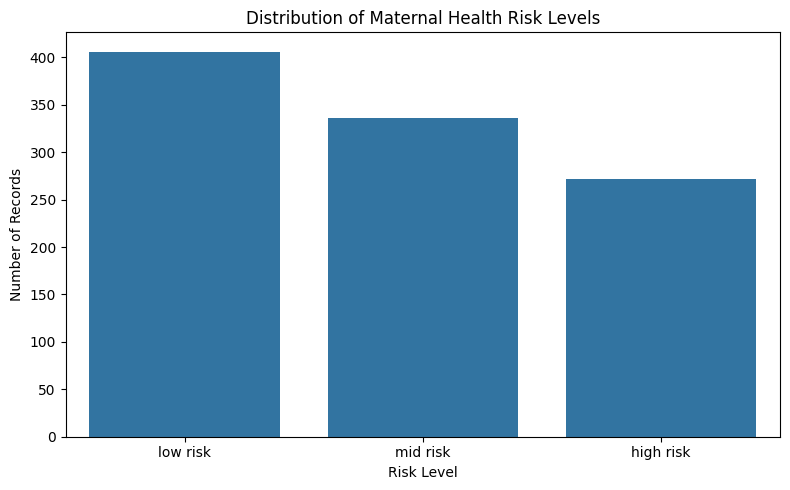

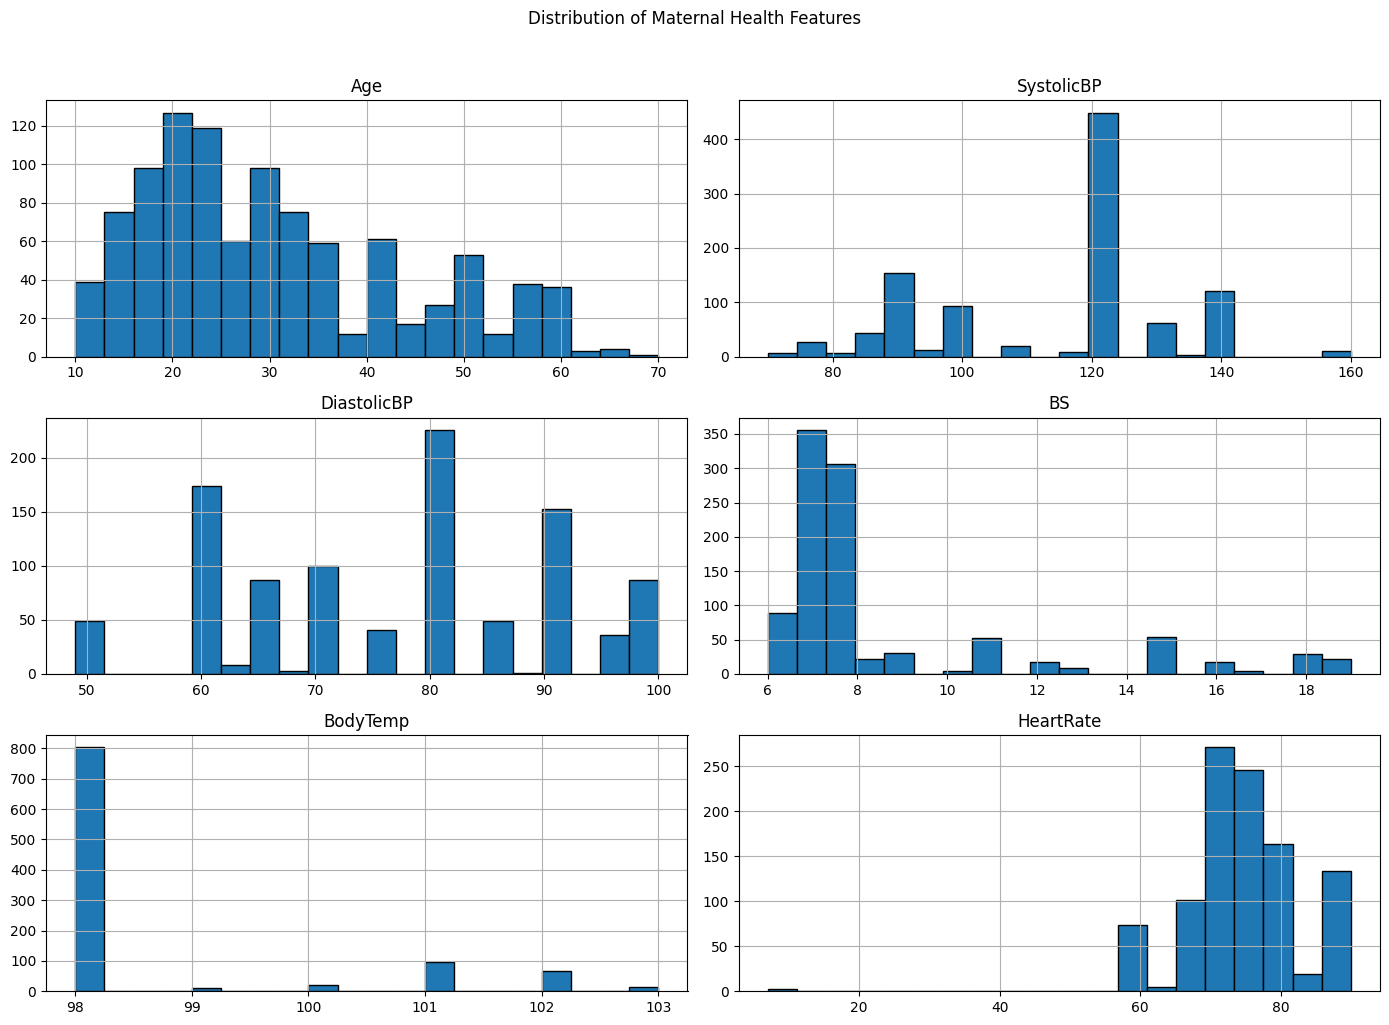

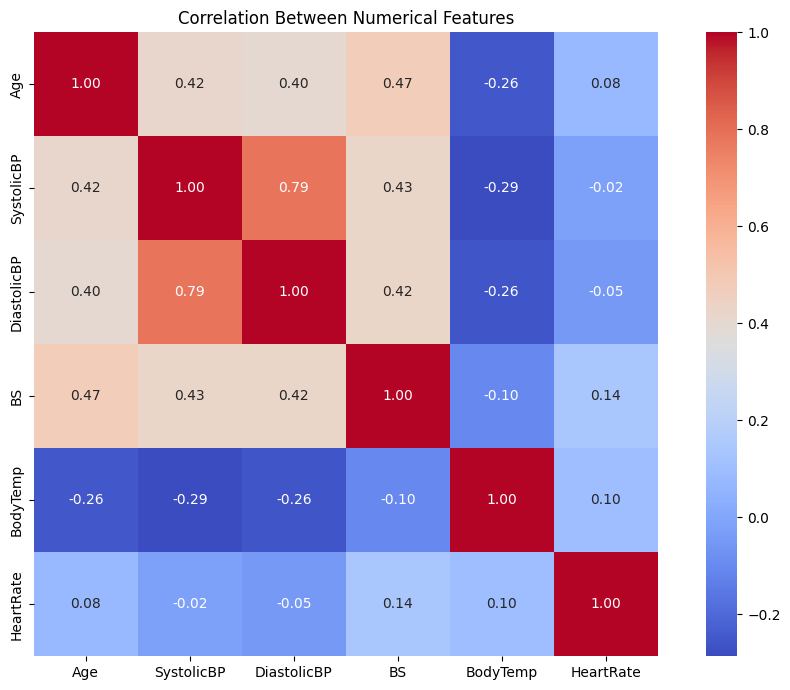

In [ ]:

# Cell 5: Exploratory Data Analysis (EDA)

# 1. Distribution of maternal risk levels
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x="RiskLevel",
    order=df["RiskLevel"].value_counts().index
)
plt.title("Distribution of Maternal Health Risk Levels")
plt.xlabel("Risk Level")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


# 2. Distribution of numerical features
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

df[numeric_cols].hist(
    figsize=(14, 10),
    bins=20,
    edgecolor="black"
)
plt.suptitle("Distribution of Maternal Health Features", y=1.02)
plt.tight_layout()
plt.show()


# 3. Correlation between numerical features
plt.figure(figsize=(10, 7))
sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    square=True
)
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()


In [ ]:

# Cell 6: Investigate duplicate patterns

FEATURES = [
    "Age",
    "SystolicBP",
    "DiastolicBP",
    "BS",
    "BodyTemp",
    "HeartRate"
]

TARGET = "RiskLevel"

# Count unique complete records
print("Total records:", len(df))
print("Unique complete records:", len(df.drop_duplicates()))
print("Exact duplicate rows beyond first occurrences:", df.duplicated().sum())

# Check whether identical input measurements ever have different labels
label_counts = (
    df.groupby(FEATURES, dropna=False)[TARGET]
      .nunique()
)

conflicting_profiles = label_counts[label_counts > 1]

print(
    "\nUnique measurement profiles with conflicting labels:",
    len(conflicting_profiles)
)

# Examine how frequently measurement profiles repeat
profile_frequency = (
    df.groupby(FEATURES, dropna=False)
      .size()
      .rename("Occurrences")
      .sort_values(ascending=False)
)

print("\nMost frequently repeated measurement profiles:")
display(profile_frequency.head(10).to_frame())

# Show conflicting examples, if any
if len(conflicting_profiles) > 0:
    conflict_index = conflicting_profiles.index
    print("\nExamples of conflicting profiles:")
    display(
        df.set_index(FEATURES)
          .loc[conflict_index]
          .head(20)
    )
else:
    print("No conflicting labels found for identical feature profiles.")


Total records: 1014
Unique complete records: 452
Exact duplicate rows beyond first occurrences: 562

Unique measurement profiles with conflicting labels: 35

Most frequently repeated measurement profiles:


,,,,,,Occurrences
Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,
19,120,80,7.0,98.0,70,34
48,120,80,11.0,98.0,88,24
31,120,60,6.1,98.0,76,20
55,140,95,19.0,98.0,77,10
40,160,100,19.0,98.0,77,10
60,120,85,15.0,98.0,60,9
40,120,95,11.0,98.0,80,9
54,140,100,15.0,98.0,66,9
32,140,90,18.0,98.0,88,9



Examples of conflicting profiles:


RiskLevel
Age SystolicBP DiastolicBP BS  BodyTemp HeartRate           
12  90         60          7.5 102.0    66          low risk
                                        66          mid risk
                                        66          mid risk
                                        66          low risk
    95         60          6.9 98.0     65          mid risk
                                        65          low risk
                                        65          mid risk
                                        65          mid risk
13  90         65          7.5 101.0    80          low risk
                                        80         high risk
                                        80          low risk
15  120        80          7.5 98.0     70          mid risk
                                        70          low risk
                                        70          low risk
                                        70          low risk
                                        70          mid risk
16  100        70          6.9 98.0     80          mid risk
                                        80          low risk
                                        80          mid risk
                                        80          mid risk

In [ ]:

# Cell 6A: Clear investigation of repeated measurements

FEATURES = [
    "Age", "SystolicBP", "DiastolicBP",
    "BS", "BodyTemp", "HeartRate"
]
TARGET = "RiskLevel"

# Count how often each exact measurement profile occurs
profile_summary = (
    df.groupby(FEATURES, dropna=False)
      .agg(
          occurrences=(TARGET, "size"),
          number_of_labels=(TARGET, "nunique")
      )
      .reset_index()
)

conflicts = profile_summary[
    profile_summary["number_of_labels"] > 1
].copy()

print("Total records:", len(df))
print("Unique measurement profiles:", len(profile_summary))
print("Profiles repeated more than once:",
      (profile_summary["occurrences"] > 1).sum())
print("Profiles with conflicting risk labels:", len(conflicts))

# Display the conflicting labels in a readable format
if not conflicts.empty:
    conflict_details = df.merge(
        conflicts[FEATURES],
        on=FEATURES,
        how="inner"
    )

    print("\nExamples of conflicting profiles and their labels:")
    display(
        conflict_details
        .sort_values(FEATURES)
        .head(20)
    )
else:
    print("No conflicting risk labels found.")


Total records: 1014
Unique measurement profiles: 416
Profiles repeated more than once: 286
Profiles with conflicting risk labels: 35

Examples of conflicting profiles and their labels:


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
88,12,90,60,7.5,102.0,66,low risk
108,12,90,60,7.5,102.0,66,mid risk
172,12,90,60,7.5,102.0,66,mid risk
197,12,90,60,7.5,102.0,66,low risk
8,12,95,60,6.9,98.0,65,mid risk
32,12,95,60,6.9,98.0,65,low risk
48,12,95,60,6.9,98.0,65,mid risk
145,12,95,60,6.9,98.0,65,mid risk
97,13,90,65,7.5,101.0,80,low risk
117,13,90,65,7.5,101.0,80,high risk


In [ ]:

# Cell 7: Quantify conflicting labels

# Summarize labels for each unique measurement profile
profile_labels = (
    df.groupby(FEATURES)[TARGET]
      .agg(
          records="size",
          unique_labels="nunique",
          observed_labels=lambda s: ", ".join(sorted(s.unique()))
      )
      .reset_index()
)

conflicting_profiles = profile_labels[
    profile_labels["unique_labels"] > 1
].copy()

print("Total records:", len(df))
print("Unique feature profiles:", len(profile_labels))
print("Conflicting feature profiles:", len(conflicting_profiles))
print(
    "Records belonging to conflicting profiles:",
    int(conflicting_profiles["records"].sum())
)

print("\nHow many labels occur per profile?")
display(
    profile_labels["unique_labels"]
    .value_counts()
    .sort_index()
    .rename_axis("Number of distinct labels")
    .to_frame("Number of profiles")
)

print("\nLargest conflicting profiles:")
display(
    conflicting_profiles
    .sort_values(
        ["records", "unique_labels"],
        ascending=False
    )
    .head(15)
)

print("\nOverall label distribution:")
display(df[TARGET].value_counts())


Total records: 1014
Unique feature profiles: 416
Conflicting feature profiles: 35
Records belonging to conflicting profiles: 215

How many labels occur per profile?


,Number of profiles
Number of distinct labels,
1,381
2,34
3,1



Largest conflicting profiles:


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,records,unique_labels,observed_labels
109,19,120,80,7.0,98.0,70,34,2,"low risk, mid risk"
354,48,120,80,11.0,98.0,88,24,3,"high risk, low risk, mid risk"
270,31,120,60,6.1,98.0,76,20,2,"low risk, mid risk"
328,40,120,95,11.0,98.0,80,9,2,"high risk, mid risk"
368,50,130,100,16.0,98.0,75,9,2,"high risk, mid risk"
406,60,120,85,15.0,98.0,60,9,2,"high risk, mid risk"
68,17,85,60,9.0,102.0,86,7,2,"high risk, mid risk"
53,15,120,80,7.5,98.0,70,5,2,"low risk, mid risk"
306,35,120,60,6.1,98.0,76,5,2,"low risk, mid risk"
4,12,90,60,7.5,102.0,66,4,2,"low risk, mid risk"



Overall label distribution:


,count
RiskLevel,
low risk,406
mid risk,336
high risk,272


In [ ]:

# Cell 8: Create feature-profile groups and inspect CV folds

from sklearn.model_selection import StratifiedGroupKFold

FEATURES = [
    "Age", "SystolicBP", "DiastolicBP",
    "BS", "BodyTemp", "HeartRate"
]
TARGET = "RiskLevel"

X = df[FEATURES].copy()
y = df[TARGET].copy()

# Identical input profiles receive the same group ID.
# These IDs are used only for splitting, not as model features.
groups = (
    df.groupby(FEATURES, sort=False, dropna=False)
      .ngroup()
      .to_numpy()
)

print("Records:", len(X))
print("Unique feature-profile groups:", len(np.unique(groups)))
print("Target classes:", sorted(y.unique()))

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_results = []

for fold, (train_idx, valid_idx) in enumerate(
    cv.split(X, y, groups=groups), start=1
):
    train_groups = set(groups[train_idx])
    valid_groups = set(groups[valid_idx])

    # Check that no feature profile crosses the split
    overlap = train_groups.intersection(valid_groups)

    train_counts = y.iloc[train_idx].value_counts()
    valid_counts = y.iloc[valid_idx].value_counts()

    fold_results.append({
        "Fold": fold,
        "Train records": len(train_idx),
        "Validation records": len(valid_idx),
        "Train groups": len(train_groups),
        "Validation groups": len(valid_groups),
        "Overlapping groups": len(overlap),
        "Train classes present": train_counts.size,
        "Validation classes present": valid_counts.size,
        "Validation low risk": valid_counts.get("low risk", 0),
        "Validation mid risk": valid_counts.get("mid risk", 0),
        "Validation high risk": valid_counts.get("high risk", 0)
    })

fold_report = pd.DataFrame(fold_results)
display(fold_report)

if (fold_report["Overlapping groups"] == 0).all():
    print("PASS: Identical feature profiles do not cross folds.")
else:
    print("WARNING: Group overlap detected; investigate before proceeding.")

if (fold_report["Validation classes present"] == 3).all():
    print("PASS: All three classes appear in every validation fold.")
else:
    print("WARNING: At least one fold is missing a class.")


Records: 1014
Unique feature-profile groups: 416
Target classes: ['high risk', 'low risk', 'mid risk']


,Fold,Train records,Validation records,Train groups,Validation groups,Overlapping groups,Train classes present,Validation classes present,Validation low risk,Validation mid risk,Validation high risk
0,1,844,170,334,82,0,3,3,71,57,42
1,2,753,261,330,86,0,3,3,90,125,46
2,3,823,191,332,84,0,3,3,79,41,71
3,4,811,203,333,83,0,3,3,83,55,65
4,5,825,189,335,81,0,3,3,83,58,48


PASS: Identical feature profiles do not cross folds.
PASS: All three classes appear in every validation fold.


In [ ]:

# Restore dataset upload and loading

import pandas as pd
from pathlib import Path
from google.colab import files

# Reuse an existing DATA_PATH if available; otherwise upload the CSV
if "DATA_PATH" in globals() and Path(DATA_PATH).exists():
    csv_path = Path(DATA_PATH)
else:
    uploaded = files.upload()

    csv_files = [
        filename for filename in uploaded
        if filename.lower().endswith(".csv")
    ]

    if not csv_files:
        raise ValueError(
            "No CSV file found. Please upload the maternal health CSV."
        )

    csv_path = Path(csv_files[0])

DATA_PATH = csv_path
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("File:", DATA_PATH.name)
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())


Saving maternal_health_risk.csv to maternal_health_risk.csv
Dataset loaded successfully!
File: maternal_health_risk.csv
Shape: (1014, 7)
Columns: ['Age', 'SystolicBP', 'DiastolicBP', 'BS', 'BodyTemp', 'HeartRate', 'RiskLevel']


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.0,98.0,86,high risk
1,35,140,90,13.0,98.0,70,high risk
2,29,90,70,8.0,100.0,80,high risk
3,30,140,85,7.0,98.0,70,high risk
4,35,120,60,6.1,98.0,76,low risk


In [ ]:

# ============================================================
# CELL 9: BASELINE MODEL COMPARISON
# MaternalRisk AI
# ============================================================

import warnings
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    f1_score,
    recall_score,
    balanced_accuracy_score
)

# ------------------------------------------------------------
# 1. CHECK PREREQUISITES
# ------------------------------------------------------------

required_variables = ["df", "FEATURES", "TARGET"]

missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    raise NameError(
        f"Missing prerequisite(s): {missing}. "
        "Run the dataset-loading and feature/target definition "
        "cells before Cell 9."
    )

RANDOM_STATE = globals().get("RANDOM_STATE", 42)

X = df[FEATURES].copy()
y = df[TARGET].astype(str).str.strip().str.lower().copy()

# ------------------------------------------------------------
# 2. CHECK TARGET LABELS
# ------------------------------------------------------------

CLASS_ORDER = ["low risk", "mid risk", "high risk"]

unexpected_labels = sorted(set(y.unique()) - set(CLASS_ORDER))

if unexpected_labels:
    raise ValueError(
        f"Unexpected target labels: {unexpected_labels}. "
        "Check the target column and its label formatting."
    )

if y.isna().any():
    raise ValueError("Target contains missing values.")

# ------------------------------------------------------------
# 3. MLP WRAPPER FOR STRING TARGET LABELS
# ------------------------------------------------------------

class EncodedMLPClassifier(ClassifierMixin, BaseEstimator):

    def __init__(
        self,
        hidden_layer_sizes=(64, 32),
        max_iter=2000,
        random_state=42
    ):
        self.hidden_layer_sizes = hidden_layer_sizes
        self.max_iter = max_iter
        self.random_state = random_state

    def fit(self, X, y):
        self.label_encoder_ = LabelEncoder()
        y_encoded = self.label_encoder_.fit_transform(y)

        self.model_ = MLPClassifier(
            hidden_layer_sizes=self.hidden_layer_sizes,
            max_iter=self.max_iter,
            early_stopping=False,
            random_state=self.random_state
        )

        self.model_.fit(X, y_encoded)
        self.classes_ = self.label_encoder_.classes_
        return self

    def predict(self, X):
        encoded_predictions = self.model_.predict(X).astype(int)
        return self.label_encoder_.inverse_transform(
            encoded_predictions
        )

# ------------------------------------------------------------
# 4. GROUPED STRATIFIED CROSS-VALIDATION
# ------------------------------------------------------------

groups = df.groupby(
    FEATURES,
    sort=False,
    dropna=False
).ngroup().to_numpy()

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

folds = list(cv.split(X, y, groups=groups))

# Verify that no identical feature profiles cross a fold
for fold_number, (train_idx, val_idx) in enumerate(folds, start=1):
    train_groups = set(groups[train_idx])
    val_groups = set(groups[val_idx])

    assert train_groups.isdisjoint(val_groups), (
        f"Group leakage detected in fold {fold_number}"
    )

print("Grouped 5-fold cross-validation ready.")
print("Dataset shape:", X.shape)
print("Class counts:")
print(y.value_counts())
print("Fold sizes:", [
    (len(train_idx), len(val_idx))
    for train_idx, val_idx in folds
])

# ------------------------------------------------------------
# 5. DEFINE FIVE BASELINE MODELS
# ------------------------------------------------------------

models = {
    "Multinomial Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=3000,
            random_state=RANDOM_STATE
        ))
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(
            random_state=RANDOM_STATE
        ))
    ]),

    "K-Nearest Neighbors": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Support Vector Machine (RBF)": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf"))
    ]),

    "Multilayer Perceptron": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", EncodedMLPClassifier(
            hidden_layer_sizes=(64, 32),
            max_iter=2000,
            random_state=RANDOM_STATE
        ))
    ])
}

# ------------------------------------------------------------
# 6. METRIC SCORERS
# ------------------------------------------------------------

def macro_f1_scorer(estimator, X_val, y_true):
    predictions = estimator.predict(X_val)
    return f1_score(
        y_true,
        predictions,
        average="macro",
        zero_division=0
    )

def high_risk_recall_scorer(estimator, X_val, y_true):
    predictions = estimator.predict(X_val)
    return recall_score(
        (np.asarray(y_true) == "high risk").astype(int),
        (np.asarray(predictions) == "high risk").astype(int),
        zero_division=0
    )

def balanced_accuracy_scorer(estimator, X_val, y_true):
    predictions = estimator.predict(X_val)
    return balanced_accuracy_score(y_true, predictions)

scoring = {
    "macro_f1": macro_f1_scorer,
    "high_risk_recall": high_risk_recall_scorer,
    "balanced_accuracy": balanced_accuracy_scorer
}

# ------------------------------------------------------------
# 7. RUN CROSS-VALIDATION
# ------------------------------------------------------------

results = []

for model_name, pipeline in models.items():
    print(f"\nEvaluating: {model_name}")

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=folds,
        scoring=scoring,
        return_train_score=False,
        n_jobs=1,
        error_score="raise"
    )

    results.append({
        "Model": model_name,
        "Macro F1 Mean": scores["test_macro_f1"].mean(),
        "Macro F1 SD": scores["test_macro_f1"].std(),
        "High-Risk Recall Mean":
            scores["test_high_risk_recall"].mean(),
        "High-Risk Recall SD":
            scores["test_high_risk_recall"].std(),
        "Balanced Accuracy Mean":
            scores["test_balanced_accuracy"].mean(),
        "Balanced Accuracy SD":
            scores["test_balanced_accuracy"].std()
    })

results_df = pd.DataFrame(results).sort_values(
    "Macro F1 Mean",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 80)
print("BASELINE MODEL COMPARISON")
print("=" * 80)

display(
    results_df.style.format({
        col: "{:.4f}"
        for col in results_df.columns
        if col != "Model"
    })
)

print(
    "\nInterpretation: these are grouped cross-validation "
    "estimates, not external clinical validation."
)


Grouped 5-fold cross-validation ready.
Dataset shape: (1014, 6)
Class counts:
RiskLevel
low risk     406
mid risk     336
high risk    272
Name: count, dtype: int64
Fold sizes: [(844, 170), (753, 261), (823, 191), (811, 203), (825, 189)]

Evaluating: Multinomial Logistic Regression

Evaluating: Decision Tree

Evaluating: K-Nearest Neighbors

Evaluating: Support Vector Machine (RBF)

Evaluating: Multilayer Perceptron

BASELINE MODEL COMPARISON


,Model,Macro F1 Mean,Macro F1 SD,High-Risk Recall Mean,High-Risk Recall SD,Balanced Accuracy Mean,Balanced Accuracy SD
0,Support Vector Machine (RBF),0.6443,0.0329,0.8057,0.0289,0.6595,0.0266
1,Decision Tree,0.6301,0.0625,0.7903,0.0285,0.6508,0.0503
2,Multilayer Perceptron,0.6161,0.0506,0.7878,0.1098,0.6314,0.0361
3,Multinomial Logistic Regression,0.5869,0.0234,0.6959,0.0348,0.6024,0.0198
4,K-Nearest Neighbors,0.5408,0.0593,0.6984,0.1405,0.5598,0.0726



Interpretation: these are grouped cross-validation estimates, not external clinical validation.


Generating out-of-fold predictions: Multinomial Logistic Regression
Generating out-of-fold predictions: Decision Tree
Generating out-of-fold predictions: K-Nearest Neighbors
Generating out-of-fold predictions: Support Vector Machine (RBF)
Generating out-of-fold predictions: Multilayer Perceptron

Out-of-fold predictions completed.

POOLED OUT-OF-FOLD METRICS


,Model,Pooled Macro F1,Pooled Balanced Accuracy
0,Support Vector Machine (RBF),0.6492,0.6625
1,Decision Tree,0.6323,0.6481
2,Multilayer Perceptron,0.6190,0.6323
3,Multinomial Logistic Regression,0.5917,0.6017
4,K-Nearest Neighbors,0.5511,0.5640



CLASSIFICATION REPORT: Multinomial Logistic Regression
              precision    recall  f1-score   support

    low risk     0.6276    0.8054    0.7055       406
    mid risk     0.4292    0.2976    0.3515       336
   high risk     0.7346    0.7022    0.7180       272

    accuracy                         0.6095      1014
   macro avg     0.5971    0.6017    0.5917      1014
weighted avg     0.5906    0.6095    0.5916      1014


CLASSIFICATION REPORT: Decision Tree
              precision    recall  f1-score   support

    low risk     0.6598    0.7931    0.7204       406
    mid risk     0.5581    0.3571    0.4356       336
   high risk     0.6945    0.7941    0.7410       272

    accuracy                         0.6489      1014
   macro avg     0.6375    0.6481    0.6323      1014
weighted avg     0.6354    0.6489    0.6315      1014


CLASSIFICATION REPORT: K-Nearest Neighbors
              precision    recall  f1-score   support

    low risk     0.5706    0.7167    0.6354  

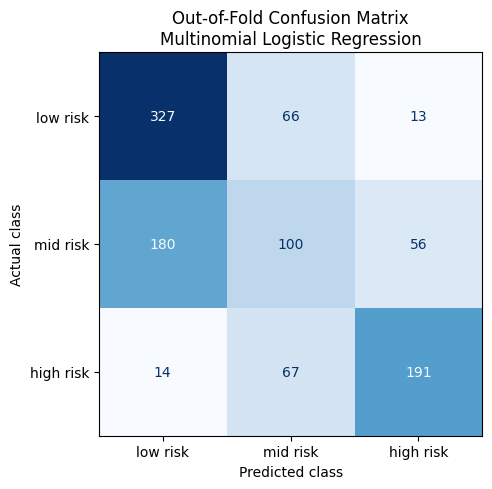

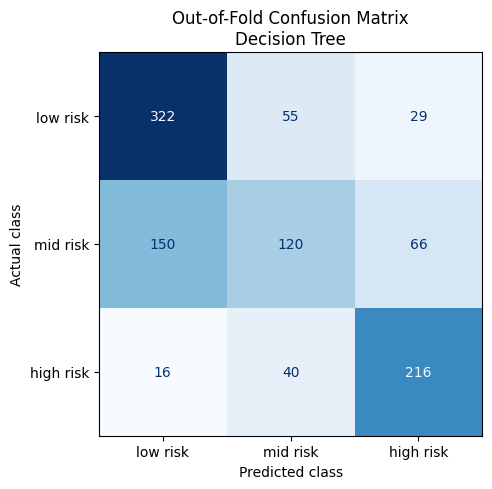

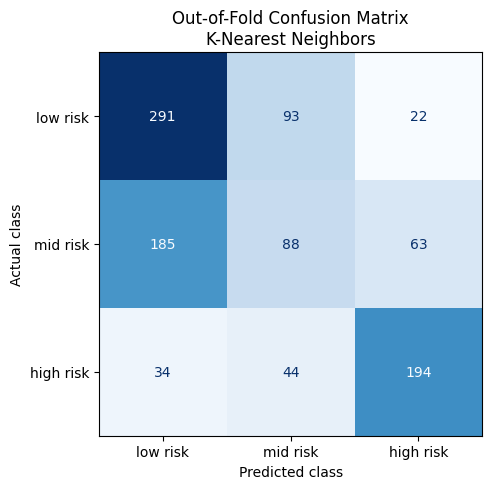

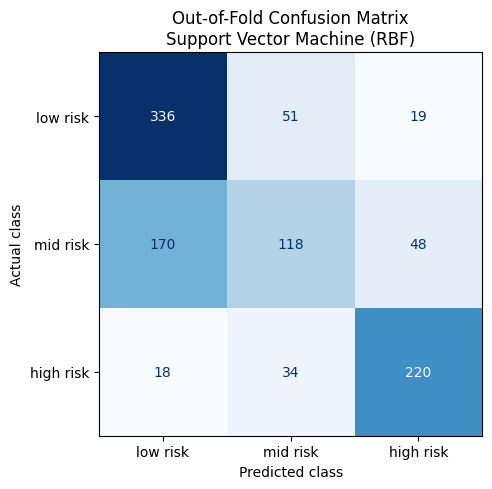

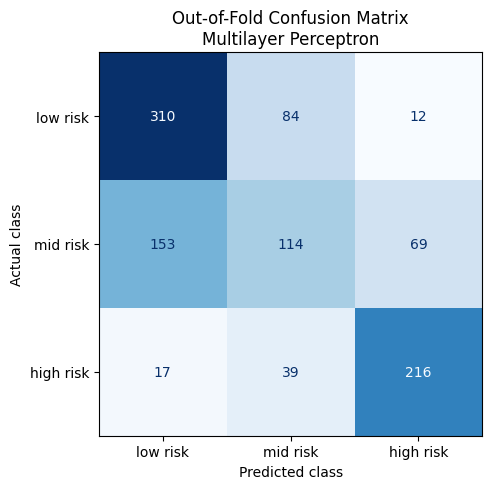


Cell 10 complete.


In [ ]:

# ============================================================
# CELL 10: OUT-OF-FOLD PREDICTIONS AND CONFUSION MATRICES
# MaternalRisk AI
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    f1_score,
    balanced_accuracy_score
)

# Consistent class ordering for all matrices and reports.
CLASS_ORDER = ["low risk", "mid risk", "high risk"]

# Store one held-out prediction per record for each model.
oof_predictions = {}

for model_name, pipeline in models.items():
    print(f"Generating out-of-fold predictions: {model_name}")

    predictions = np.empty(len(y), dtype=object)

    for train_idx, val_idx in folds:
        fold_model = clone(pipeline)

        fold_model.fit(
            X.iloc[train_idx],
            y.iloc[train_idx]
        )

        predictions[val_idx] = fold_model.predict(
            X.iloc[val_idx]
        )

    oof_predictions[model_name] = predictions

print("\nOut-of-fold predictions completed.")

# ------------------------------------------------------------
# 1. Pooled out-of-fold metrics
# ------------------------------------------------------------

pooled_results = []

for model_name, predictions in oof_predictions.items():
    pooled_results.append({
        "Model": model_name,
        "Pooled Macro F1": f1_score(
            y,
            predictions,
            labels=CLASS_ORDER,
            average="macro",
            zero_division=0
        ),
        "Pooled Balanced Accuracy": balanced_accuracy_score(
            y,
            predictions
        )
    })

pooled_results_df = (
    pd.DataFrame(pooled_results)
    .sort_values("Pooled Macro F1", ascending=False)
    .reset_index(drop=True)
)

print("\nPOOLED OUT-OF-FOLD METRICS")
display(pooled_results_df.round(4))

# ------------------------------------------------------------
# 2. Per-class classification report
# ------------------------------------------------------------

for model_name, predictions in oof_predictions.items():
    print(f"\n{'=' * 65}")
    print(f"CLASSIFICATION REPORT: {model_name}")
    print("=" * 65)

    print(classification_report(
        y,
        predictions,
        labels=CLASS_ORDER,
        target_names=CLASS_ORDER,
        zero_division=0,
        digits=4
    ))

# ------------------------------------------------------------
# 3. Confusion matrix for each model
# ------------------------------------------------------------

for model_name, predictions in oof_predictions.items():
    cm = confusion_matrix(
        y,
        predictions,
        labels=CLASS_ORDER
    )

    fig, ax = plt.subplots(figsize=(6, 5))

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=CLASS_ORDER
    )

    display_cm.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(f"Out-of-Fold Confusion Matrix\n{model_name}")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")

    plt.tight_layout()
    plt.show()

print("\nCell 10 complete.")


FEATURE SUMMARY BY RISK CLASS


Age               SystolicBP                DiastolicBP         \
          median   mean    std     median    mean    std      median   mean   
RiskLevel                                                                     
high risk   35.0  36.22  13.03      130.0  124.19  20.23        90.0  85.07   
low risk    22.0  26.87  13.12      120.0  105.87  15.89        75.0  72.53   
mid risk    25.0  28.36  12.55      120.0  113.15  14.98        75.0  74.23   

                     BS              BodyTemp              HeartRate         \
             std median   mean   std   median   mean   std    median   mean   
RiskLevel                                                                     
high risk  14.11   11.0  12.12  4.17     98.0  98.90  1.56      77.0  76.74   
low risk   13.05    7.5   7.22  0.65     98.0  98.37  1.11      70.0  72.77   
mid risk   11.49    7.0   7.80  2.29     98.0  98.83  1.43      76.0  74.18   

                 
            std  
RiskLevel        
high risk  8.70  
low risk   8.29  
mid risk   6.77

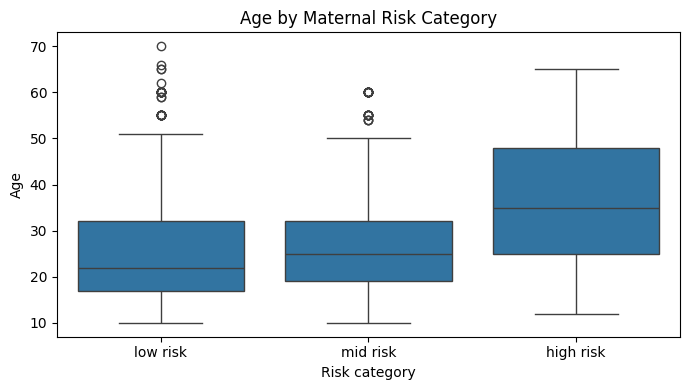

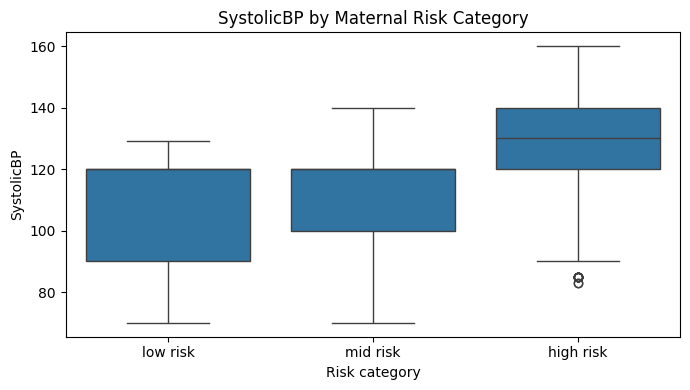

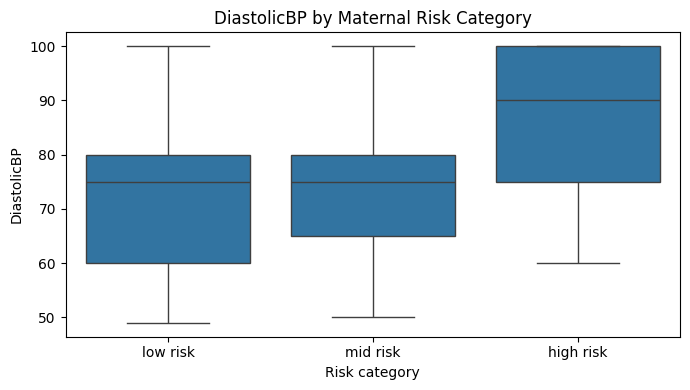

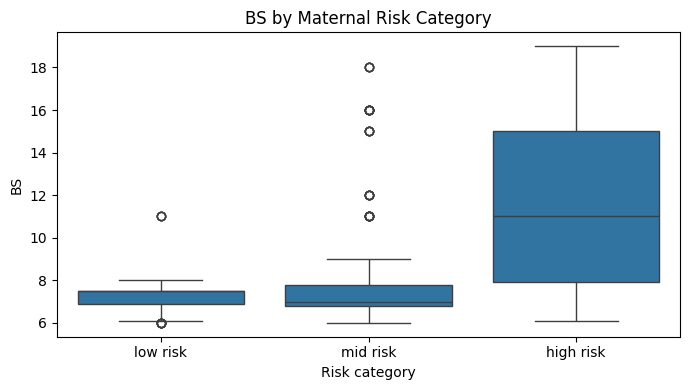

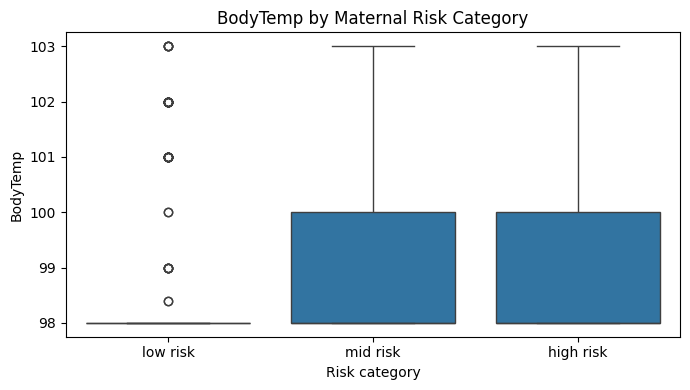

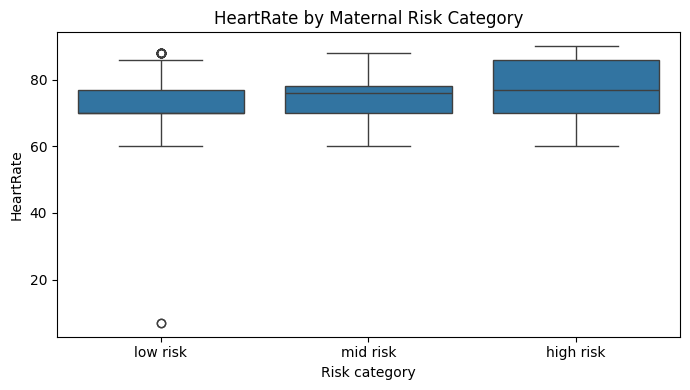

In [ ]:

# ============================================================
# CELL 11: INVESTIGATE CLASS OVERLAP
# MaternalRisk AI
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Compare feature distributions by risk category
print("FEATURE SUMMARY BY RISK CLASS")

display(
    df.groupby(TARGET)[FEATURES]
      .agg(["median", "mean", "std"])
      .round(2)
)

# Visualize feature distributions
for feature in FEATURES:
    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df,
        x=TARGET,
        y=feature,
        order=["low risk", "mid risk", "high risk"]
    )

    plt.title(f"{feature} by Maternal Risk Category")
    plt.xlabel("Risk category")
    plt.ylabel(feature)
    plt.tight_layout()
    plt.show()


Feature correlations with each risk-class indicator:


,risk_high risk,risk_low risk,risk_mid risk
Age,0.285,-0.182,-0.079
SystolicBP,0.362,-0.326,-0.002
DiastolicBP,0.376,-0.231,-0.113
BS,0.625,-0.374,-0.199
BodyTemp,0.103,-0.177,0.086
HeartRate,0.183,-0.155,-0.011


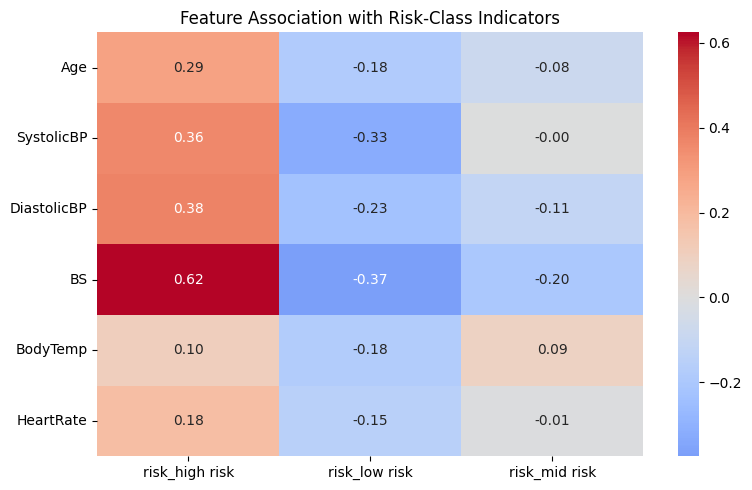

In [ ]:

# ============================================================
# CELL 12: FEATURE ASSOCIATION WITH RISK LABELS
# MaternalRisk AI
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Encode risk categories as indicator columns
risk_indicators = pd.get_dummies(
    df[TARGET].astype(str).str.strip().str.lower(),
    prefix="risk",
    dtype=int
)

# Correlation between each numeric feature and each risk indicator
association = pd.concat(
    [df[FEATURES].reset_index(drop=True), risk_indicators.reset_index(drop=True)],
    axis=1
).corr().loc[FEATURES, risk_indicators.columns]

print("Feature correlations with each risk-class indicator:")
display(association.round(3))

plt.figure(figsize=(8, 5))
sns.heatmap(
    association,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Feature Association with Risk-Class Indicators")
plt.tight_layout()
plt.show()


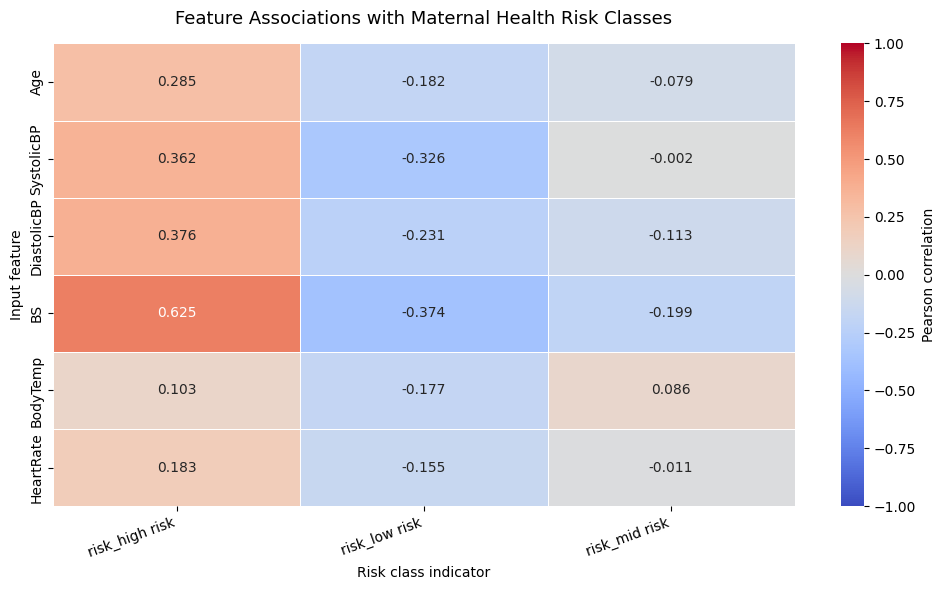

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# CELL 13: EXPORT CORRELATION HEATMAP AS SVG
# MaternalRisk AI
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

risk_indicators = pd.get_dummies(
    df[TARGET].astype(str).str.strip().str.lower(),
    prefix="risk",
    dtype=int
)

association = pd.concat(
    [
        df[FEATURES].reset_index(drop=True),
        risk_indicators.reset_index(drop=True)
    ],
    axis=1
).corr().loc[FEATURES, risk_indicators.columns]

plt.figure(figsize=(10, 6))

sns.heatmap(
    association,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"label": "Pearson correlation"}
)

plt.title(
    "Feature Associations with Maternal Health Risk Classes",
    fontsize=13,
    pad=14
)
plt.xlabel("Risk class indicator")
plt.ylabel("Input feature")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()

svg_path = "maternalrisk_feature_class_correlation.svg"

plt.savefig(
    svg_path,
    format="svg",
    bbox_inches="tight"
)

plt.show()
files.download(svg_path)

In [ ]:

# ============================================================
# CELL 14: GROUPED HYPERPARAMETER TUNING
# MaternalRisk AI
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, recall_score

# ------------------------------------------------------------
# 1. Confirm that the previous cells have been executed
# ------------------------------------------------------------

required_variables = ["X", "y", "folds", "RANDOM_STATE"]
missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        f"Missing variables: {missing_variables}. "
        "Please run the earlier data preparation and "
        "grouped cross-validation cells first."
    )

print("Features:", X.shape)
print("Labels:", y.shape)
print("Grouped CV folds:", len(folds))

# ------------------------------------------------------------
# 2. Define evaluation metrics
# ------------------------------------------------------------

def macro_f1_scorer(estimator, X_val, y_true):
    predictions = estimator.predict(X_val)
    return f1_score(
        y_true,
        predictions,
        average="macro",
        zero_division=0
    )

def high_risk_recall_scorer(estimator, X_val, y_true):
    predictions = estimator.predict(X_val)

    true_high = (np.asarray(y_true) == "high risk").astype(int)
    pred_high = (np.asarray(predictions) == "high risk").astype(int)

    return recall_score(
        true_high,
        pred_high,
        zero_division=0
    )

scoring = {
    "macro_f1": macro_f1_scorer,
    "high_risk_recall": high_risk_recall_scorer
}

# ------------------------------------------------------------
# 3. Define models and parameter grids
# ------------------------------------------------------------

models_to_tune = {
    "SVM": {
        "pipeline": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("classifier", SVC(kernel="rbf"))
        ]),
        "parameters": {
            "classifier__C": [0.1, 1, 10],
            "classifier__gamma": ["scale", 0.01, 0.1],
            "classifier__class_weight": [None, "balanced"]
        }
    },

    "Decision Tree": {
        "pipeline": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("classifier", DecisionTreeClassifier(
                random_state=RANDOM_STATE
            ))
        ]),
        "parameters": {
            "classifier__max_depth": [None, 3, 5, 8, 12],
            "classifier__min_samples_leaf": [1, 3, 5, 10],
            "classifier__class_weight": [None, "balanced"]
        }
    },

    "Logistic Regression": {
        "pipeline": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("classifier", LogisticRegression(
                max_iter=3000,
                random_state=RANDOM_STATE
            ))
        ]),
        "parameters": {
            "classifier__C": [0.1, 1, 10],
            "classifier__class_weight": [None, "balanced"]
        }
    }
}

# ------------------------------------------------------------
# 4. Search using the SAME grouped folds as the baseline
# ------------------------------------------------------------

tuning_results = {}
best_estimators = {}
summary_rows = []

for model_name, config in models_to_tune.items():

    print("\n" + "=" * 65)
    print("Tuning:", model_name)
    print("=" * 65)

    search = GridSearchCV(
        estimator=config["pipeline"],
        param_grid=config["parameters"],
        scoring=scoring,
        refit="macro_f1",
        cv=folds,
        n_jobs=1,
        return_train_score=False,
        error_score="raise"
    )

    search.fit(X, y)

    tuning_results[model_name] = search
    best_estimators[model_name] = clone(
        search.best_estimator_
    )

    best_index = search.best_index_

    best_high_recall = search.cv_results_[
        "mean_test_high_risk_recall"
    ][best_index]

    high_recall_sd = search.cv_results_[
        "std_test_high_risk_recall"
    ][best_index]

    summary_rows.append({
        "Model": model_name,
        "Best CV Macro F1": search.best_score_,
        "Macro F1 SD": search.cv_results_[
            "std_test_macro_f1"
        ][best_index],
        "High-Risk Recall": best_high_recall,
        "High-Risk Recall SD": high_recall_sd,
        "Best Parameters": search.best_params_
    })

    print("Best macro F1:", round(search.best_score_, 4))
    print("Best high-risk recall:", round(best_high_recall, 4))
    print("Best parameters:", search.best_params_)

# ------------------------------------------------------------
# 5. Display tuned model comparison
# ------------------------------------------------------------

tuning_summary = pd.DataFrame(summary_rows)

tuning_summary = tuning_summary.sort_values(
    "Best CV Macro F1",
    ascending=False
).reset_index(drop=True)

print("\nTUNED MODEL COMPARISON")
display(tuning_summary.round(4))

print(
    "\nSelection criterion: highest grouped-CV macro F1."
)
print(
    "High-risk recall is reported separately; it is not "
    "the optimization criterion."
)


Features: (1014, 6)
Labels: (1014,)
Grouped CV folds: 5

Tuning: SVM
Best macro F1: 0.669
Best high-risk recall: 0.7988
Best parameters: {'classifier__C': 10, 'classifier__class_weight': None, 'classifier__gamma': 0.01}

Tuning: Decision Tree
Best macro F1: 0.6658
Best high-risk recall: 0.8237
Best parameters: {'classifier__class_weight': None, 'classifier__max_depth': None, 'classifier__min_samples_leaf': 3}

Tuning: Logistic Regression
Best macro F1: 0.6059
Best high-risk recall: 0.7448
Best parameters: {'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}

TUNED MODEL COMPARISON


,Model,Best CV Macro F1,Macro F1 SD,High-Risk Recall,High-Risk Recall SD,Best Parameters
0,SVM,0.6690,0.0329,0.7988,0.0495,"{'classifier__C': 10, 'classifier__class_weigh..."
1,Decision Tree,0.6658,0.0487,0.8237,0.0502,"{'classifier__class_weight': None, 'classifier..."
2,Logistic Regression,0.6059,0.0468,0.7448,0.0662,"{'classifier__C': 0.1, 'classifier__class_weig..."



Selection criterion: highest grouped-CV macro F1.
High-risk recall is reported separately; it is not the optimization criterion.


In [ ]:

# ============================================================
# CELL 15: NESTED GROUPED CROSS-VALIDATION
# MaternalRisk AI
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score,
    recall_score,
    classification_report,
    confusion_matrix
)

if "groups" not in globals():
    raise NameError("Please run the earlier grouped-CV setup cell first.")

nested_predictions = {}
nested_results = []

# Each outer fold is held out from both tuning and fitting.
for model_name, config in models_to_tune.items():

    print(f"\nRunning nested CV for {model_name}...")
    oof_predictions = np.empty(len(y), dtype=object)

    for fold_number, (train_idx, test_idx) in enumerate(folds, start=1):

        X_train = X.iloc[train_idx]
        y_train = y.iloc[train_idx]
        X_test = X.iloc[test_idx]

        # Inner grouped folds are built using only outer-training data.
        inner_cv = StratifiedGroupKFold(
            n_splits=4,
            shuffle=True,
            random_state=RANDOM_STATE + fold_number
        )

        inner_folds = list(
            inner_cv.split(
                X_train,
                y_train,
                groups=np.asarray(groups)[train_idx]
            )
        )

        search = GridSearchCV(
            estimator=clone(config["pipeline"]),
            param_grid=config["parameters"],
            scoring=macro_f1_scorer,
            cv=inner_folds,
            refit=True,
            n_jobs=1,
            error_score="raise"
        )

        search.fit(X_train, y_train)
        oof_predictions[test_idx] = search.predict(X_test)

        print(
            f"  Outer fold {fold_number}/5 complete | "
            f"inner best macro F1: {search.best_score_:.3f}"
        )

    nested_predictions[model_name] = oof_predictions

    macro_f1 = f1_score(
        y, oof_predictions,
        average="macro",
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(y, oof_predictions)

    high_recall = recall_score(
        np.asarray(y) == "high risk",
        oof_predictions == "high risk",
        zero_division=0
    )

    mid_recall = recall_score(
        np.asarray(y) == "mid risk",
        oof_predictions == "mid risk",
        zero_division=0
    )

    nested_results.append({
        "Model": model_name,
        "Nested OOF Macro F1": macro_f1,
        "Nested OOF Balanced Accuracy": balanced_acc,
        "High-Risk Recall": high_recall,
        "Mid-Risk Recall": mid_recall
    })

nested_summary = pd.DataFrame(nested_results).sort_values(
    "Nested OOF Macro F1",
    ascending=False
).reset_index(drop=True)

print("\nNESTED CROSS-VALIDATION RESULTS")
display(nested_summary.round(4))

# Detailed report for the leading model
best_nested_model = nested_summary.iloc[0]["Model"]

print(f"\nClassification report: {best_nested_model}")
print(
    classification_report(
        y,
        nested_predictions[best_nested_model],
        labels=["low risk", "mid risk", "high risk"],
        zero_division=0
    )
)

print("Confusion matrix (rows = actual, columns = predicted):")
display(
    pd.DataFrame(
        confusion_matrix(
            y,
            nested_predictions[best_nested_model],
            labels=["low risk", "mid risk", "high risk"]
        ),
        index=["Actual low", "Actual mid", "Actual high"],
        columns=["Predicted low", "Predicted mid", "Predicted high"]
    )
)



Running nested CV for SVM...
  Outer fold 1/5 complete | inner best macro F1: 0.641
  Outer fold 2/5 complete | inner best macro F1: 0.655
  Outer fold 3/5 complete | inner best macro F1: 0.646
  Outer fold 4/5 complete | inner best macro F1: 0.638
  Outer fold 5/5 complete | inner best macro F1: 0.661

Running nested CV for Decision Tree...
  Outer fold 1/5 complete | inner best macro F1: 0.629
  Outer fold 2/5 complete | inner best macro F1: 0.678
  Outer fold 3/5 complete | inner best macro F1: 0.638
  Outer fold 4/5 complete | inner best macro F1: 0.652
  Outer fold 5/5 complete | inner best macro F1: 0.639

Running nested CV for Logistic Regression...
  Outer fold 1/5 complete | inner best macro F1: 0.605
  Outer fold 2/5 complete | inner best macro F1: 0.615
  Outer fold 3/5 complete | inner best macro F1: 0.604
  Outer fold 4/5 complete | inner best macro F1: 0.602
  Outer fold 5/5 complete | inner best macro F1: 0.587

NESTED CROSS-VALIDATION RESULTS


,Model,Nested OOF Macro F1,Nested OOF Balanced Accuracy,High-Risk Recall,Mid-Risk Recall
0,SVM,0.6615,0.6687,0.8015,0.4018
1,Decision Tree,0.6078,0.6178,0.7353,0.3274
2,Logistic Regression,0.5896,0.5911,0.6875,0.3542



Classification report: SVM
              precision    recall  f1-score   support

    low risk       0.65      0.80      0.72       406
    mid risk       0.57      0.40      0.47       336
   high risk       0.78      0.80      0.79       272

    accuracy                           0.67      1014
   macro avg       0.67      0.67      0.66      1014
weighted avg       0.66      0.67      0.66      1014

Confusion matrix (rows = actual, columns = predicted):


,Predicted low,Predicted mid,Predicted high
Actual low,326,60,20
Actual mid,161,135,40
Actual high,12,42,218


In [ ]:

# ============================================================
# CELL 16: NESTED CV EVALUATION PLOTS
# MaternalRisk AI
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    recall_score,
    f1_score
)
from google.colab import files

# Use the leading model's nested out-of-fold predictions
best_model_name = "SVM"
actual = np.asarray(y)
predicted = np.asarray(nested_predictions[best_model_name])

class_order = ["low risk", "mid risk", "high risk"]

cm = confusion_matrix(
    actual,
    predicted,
    labels=class_order
)

# ------------------------------------------------------------
# Plot 1: Confusion matrix
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_order,
    yticklabels=class_order,
    linewidths=0.5
)

plt.title("SVM — Nested Cross-Validation Confusion Matrix")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.tight_layout()

cm_file = "maternalrisk_svm_confusion_matrix.svg"
plt.savefig(cm_file, format="svg", bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# Plot 2: Recall by class
# ------------------------------------------------------------

class_recalls = recall_score(
    actual,
    predicted,
    labels=class_order,
    average=None,
    zero_division=0
)

recall_df = pd.DataFrame({
    "Risk class": class_order,
    "Recall": class_recalls
})

plt.figure(figsize=(8, 5))

bars = plt.bar(
    recall_df["Risk class"],
    recall_df["Recall"]
)

plt.ylim(0, 1)
plt.ylabel("Recall")
plt.xlabel("Actual risk class")
plt.title("SVM — Recall by Risk Class")
plt.axhline(
    y=np.mean(class_recalls),
    linestyle="--",
    label=f"Macro recall = {np.mean(class_recalls):.3f}"
)
plt.legend()

for bar, value in zip(bars, class_recalls):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.1%}",
        ha="center"
    )

plt.tight_layout()

recall_file = "maternalrisk_svm_class_recall.svg"
plt.savefig(recall_file, format="svg", bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# Export numerical results
# ------------------------------------------------------------

print("Class-wise recall:")
display(recall_df.round(4))

print("Saved figures:")
print(cm_file)
print(recall_file)

# Download the files one at a time
files.download(cm_file)
files.download(recall_file)


NameError: name 'nested_predictions' is not defined

In [ ]:

# ============================================================
# RECOVERY CELL: RESTORE DATA VARIABLES
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from google.colab import files

# Restore the dataset
if "df" not in globals():
    if "DATA_PATH" in globals() and Path(DATA_PATH).exists():
        df = pd.read_csv(DATA_PATH)
    else:
        uploaded = files.upload()
        csv_files = [
            name for name in uploaded
            if name.lower().endswith(".csv")
        ]

        if not csv_files:
            raise ValueError("Please upload the maternal health CSV file.")

        DATA_PATH = Path(csv_files[0])
        df = pd.read_csv(DATA_PATH)

# Restore feature and target definitions
TARGET = "RiskLevel"
FEATURES = [
    "Age",
    "SystolicBP",
    "DiastolicBP",
    "BS",
    "BodyTemp",
    "HeartRate"
]

X = df[FEATURES].copy()
y = df[TARGET].astype(str).str.strip().str.lower().copy()

print("Dataset restored:", df.shape)
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Labels:", sorted(y.unique()))

# Check whether nested predictions still exist
print(
    "Nested predictions available:",
    "nested_predictions" in globals()
)


Saving maternal_health_risk.csv to maternal_health_risk.csv
Dataset restored: (1014, 7)
X shape: (1014, 6)
y shape: (1014,)
Labels: ['high risk', 'low risk', 'mid risk']
Nested predictions available: False


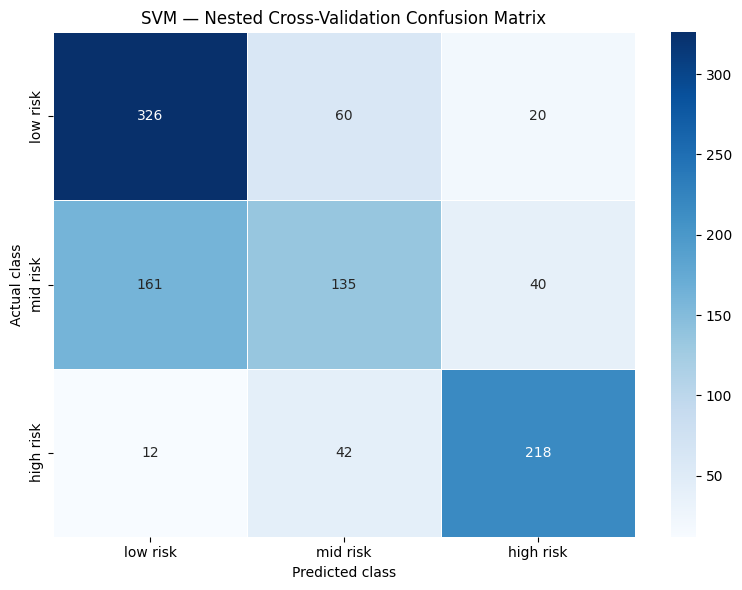

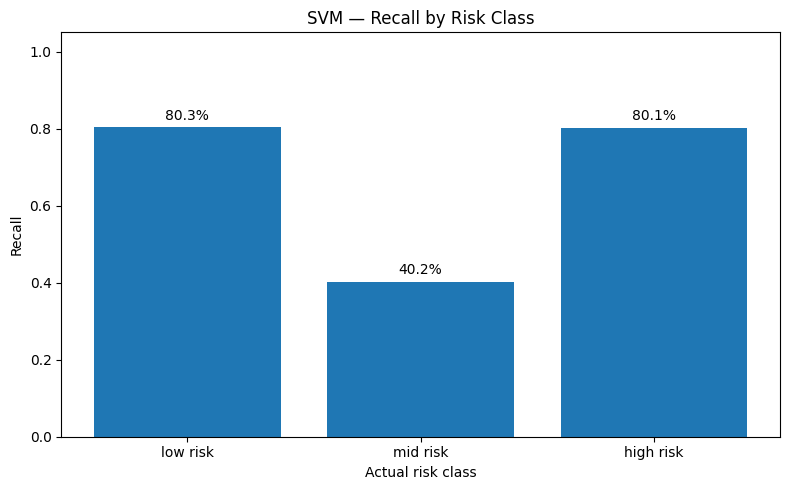

Class-wise recall:


,Risk class,Recall
0,low risk,0.8030
1,mid risk,0.4018
2,high risk,0.8015


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# CELL 16: RECREATE SVM EVALUATION PLOTS
# Uses the previously reported confusion matrix
# No model retraining required
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

class_order = ["low risk", "mid risk", "high risk"]

# Previously reported nested OOF confusion matrix
cm = np.array([
    [326,  60,  20],
    [161, 135,  40],
    [ 12,  42, 218]
])

# ------------------------------------------------------------
# Plot 1: Confusion matrix
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_order,
    yticklabels=class_order,
    linewidths=0.5
)

plt.title("SVM — Nested Cross-Validation Confusion Matrix")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.tight_layout()

cm_file = "maternalrisk_svm_confusion_matrix.svg"
plt.savefig(cm_file, format="svg", bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# Plot 2: Recall by class
# ------------------------------------------------------------

class_recalls = cm.diagonal() / cm.sum(axis=1)

recall_df = pd.DataFrame({
    "Risk class": class_order,
    "Recall": class_recalls
})

plt.figure(figsize=(8, 5))

bars = plt.bar(
    recall_df["Risk class"],
    recall_df["Recall"]
)

plt.ylim(0, 1.05)
plt.ylabel("Recall")
plt.xlabel("Actual risk class")
plt.title("SVM — Recall by Risk Class")

for bar, value in zip(bars, class_recalls):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.1%}",
        ha="center"
    )

plt.tight_layout()

recall_file = "maternalrisk_svm_class_recall.svg"
plt.savefig(recall_file, format="svg", bbox_inches="tight")
plt.show()

print("Class-wise recall:")
display(recall_df.round(4))

# Download each SVG
files.download(cm_file)
files.download(recall_file)


In [ ]:

# CELL 17: SAVE EVALUATION RESULTS

import pandas as pd
from google.colab import files

class_order = ["low risk", "mid risk", "high risk"]

# Save the confusion matrix used for the evaluation plots
cm = pd.DataFrame(
    [
        [326, 60, 20],
        [161, 135, 40],
        [12, 42, 218]
    ],
    index=["Actual low risk", "Actual mid risk", "Actual high risk"],
    columns=["Predicted low risk", "Predicted mid risk", "Predicted high risk"]
)

cm.to_csv("maternalrisk_svm_confusion_matrix.csv")

# Save class-wise recall
recall_results = pd.DataFrame({
    "Risk class": class_order,
    "Recall": [326/406, 135/336, 218/272]
})

recall_results.to_csv(
    "maternalrisk_svm_class_recall.csv",
    index=False
)

# Save nested CV comparison
nested_results_df = pd.DataFrame([
    {
        "Model": "SVM",
        "Nested OOF Macro F1": 0.6615,
        "Nested OOF Balanced Accuracy": 0.6687,
        "High-Risk Recall": 0.8015,
        "Mid-Risk Recall": 0.4018
    },
    {
        "Model": "Decision Tree",
        "Nested OOF Macro F1": 0.6078,
        "Nested OOF Balanced Accuracy": 0.6178,
        "High-Risk Recall": 0.7353,
        "Mid-Risk Recall": 0.3274
    },
    {
        "Model": "Logistic Regression",
        "Nested OOF Macro F1": 0.5896,
        "Nested OOF Balanced Accuracy": 0.5911,
        "High-Risk Recall": 0.6875,
        "Mid-Risk Recall": 0.3542
    }
])

nested_results_df.to_csv(
    "maternalrisk_nested_cv_results.csv",
    index=False
)

print("Saved three CSV files:")
print("1. maternalrisk_svm_confusion_matrix.csv")
print("2. maternalrisk_svm_class_recall.csv")
print("3. maternalrisk_nested_cv_results.csv")

files.download("maternalrisk_nested_cv_results.csv")


Saved three CSV files:
1. maternalrisk_svm_confusion_matrix.csv
2. maternalrisk_svm_class_recall.csv
3. maternalrisk_nested_cv_results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# CELL 18: CLASS-SENSITIVE SVM TUNING
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    f1_score,
    recall_score,
    balanced_accuracy_score
)

# Verify required variables
required = ["X", "y", "folds", "groups", "models_to_tune"]
missing = [v for v in required if v not in globals()]

if missing:
    raise NameError(
        f"Missing variables: {missing}. "
        "If Colab restarted, rerun the data preparation and "
        "grouped-CV setup cells first."
    )

# Use the SVM pipeline from the earlier experiment
svm_pipeline = clone(models_to_tune["SVM"]["pipeline"])

# Focus on class weights and a modest range of C values.
# The remaining SVM settings are held at the earlier best values.
param_grid = {
    "classifier__C": [1, 10],
    "classifier__gamma": [0.01, "scale"],
    "classifier__class_weight": [
        None,
        "balanced",
        {
            "low risk": 1.0,
            "mid risk": 1.5,
            "high risk": 1.0
        },
        {
            "low risk": 1.0,
            "mid risk": 2.0,
            "high risk": 1.0
        },
        {
            "low risk": 1.0,
            "mid risk": 1.0,
            "high risk": 1.5
        }
    ]
}

# Macro F1 is still the primary selection metric.
# We will inspect class-specific recall after tuning.
search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    scoring=macro_f1_scorer,
    cv=folds,
    refit=True,
    n_jobs=1,
    return_train_score=False,
    error_score="raise"
)

search.fit(X, y)

print("Best grouped-CV macro F1:", round(search.best_score_, 4))
print("Best parameters:")
print(search.best_params_)

# Summarize all parameter combinations
results = pd.DataFrame(search.cv_results_)

columns_to_show = [
    "mean_test_score",
    "std_test_score",
    "param_classifier__C",
    "param_classifier__gamma",
    "param_classifier__class_weight"
]

tuning_comparison = results[columns_to_show].copy()
tuning_comparison = tuning_comparison.rename(columns={
    "mean_test_score": "Mean CV Macro F1",
    "std_test_score": "CV Macro F1 SD",
    "param_classifier__C": "C",
    "param_classifier__gamma": "Gamma",
    "param_classifier__class_weight": "Class weights"
})

tuning_comparison = tuning_comparison.sort_values(
    "Mean CV Macro F1",
    ascending=False
).reset_index(drop=True)

display(tuning_comparison.round(4))


Best grouped-CV macro F1: 0.669
Best parameters:
{'classifier__C': 10, 'classifier__class_weight': None, 'classifier__gamma': 0.01}


,Mean CV Macro F1,CV Macro F1 SD,C,Gamma,Class weights
0,0.6690,0.0329,10,0.01,None
1,0.6466,0.0203,10,0.01,"{'low risk': 1.0, 'mid risk': 1.0, 'high risk'..."
2,0.6443,0.0329,1,scale,None
3,0.6435,0.0261,1,scale,balanced
4,0.6432,0.0354,10,0.01,balanced
5,0.6339,0.0321,10,scale,None
6,0.6275,0.0400,10,scale,"{'low risk': 1.0, 'mid risk': 1.0, 'high risk'..."
7,0.6261,0.0229,1,scale,"{'low risk': 1.0, 'mid risk': 1.0, 'high risk'..."
8,0.6260,0.0257,1,scale,"{'low risk': 1.0, 'mid risk': 1.5, 'high risk'..."
9,0.6222,0.0374,10,0.01,"{'low risk': 1.0, 'mid risk': 1.5, 'high risk'..."


In [ ]:

# ============================================================
# RECOVERY CELL: RESTORE GROUPS, FOLDS AND SVM CONFIGURATION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# 1. Restore feature and target variables if necessary
if "df" not in globals():
    raise NameError(
        "The dataset df is missing. Run your dataset-loading cell first."
    )

TARGET = "RiskLevel"
FEATURES = [
    "Age", "SystolicBP", "DiastolicBP",
    "BS", "BodyTemp", "HeartRate"
]

X = df[FEATURES].copy()
y = df[TARGET].astype(str).str.strip().str.lower().copy()

# 2. Group identical feature profiles together
groups = (
    df.groupby(FEATURES, sort=False, dropna=False)
      .ngroup()
      .to_numpy()
)

# 3. Recreate the original five grouped folds
RANDOM_STATE = 42

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

folds = list(cv.split(X, y, groups=groups))

# 4. Restore the SVM pipeline
svm_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", SVC(kernel="rbf"))
])

models_to_tune = {
    "SVM": {
        "pipeline": svm_pipeline,
        "parameters": {
            "classifier__C": [0.1, 1, 10],
            "classifier__gamma": ["scale", 0.01, 0.1],
            "classifier__class_weight": [None, "balanced"]
        }
    }
}

print("Recovery successful!")
print("X shape:", X.shape)
print("Number of labels:", y.nunique())
print("Number of unique-profile groups:", len(np.unique(groups)))
print("Number of CV folds:", len(folds))
print("SVM pipeline restored.")


Recovery successful!
X shape: (1014, 6)
Number of labels: 3
Number of unique-profile groups: 416
Number of CV folds: 5
SVM pipeline restored.


In [ ]:

from sklearn.metrics import f1_score
import numpy as np

def macro_f1_scorer(estimator, X_val, y_true):
    predictions = estimator.predict(X_val)
    return f1_score(
        y_true,
        predictions,
        average="macro",
        zero_division=0
    )

print("macro_f1_scorer restored successfully!")


macro_f1_scorer restored successfully!


In [ ]:

# ============================================================
# CELL 19: COMPARE CLASS-WEIGHT EFFECTS
# Diagnostic comparison using grouped CV
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    f1_score,
    recall_score,
    balanced_accuracy_score
)

# Ensure these variables exist from the recovery cells
required = ["X", "y", "folds", "svm_pipeline"]

missing = [name for name in required if name not in globals()]
if missing:
    raise NameError(
        f"Missing variables: {missing}. Run the recovery cells first."
    )

# Compare the original configuration with a mid-risk-weighted version
comparison_models = {
    "SVM — unweighted": {
        "C": 10,
        "gamma": 0.01,
        "class_weight": None
    },
    "SVM — mid-risk weight 1.5": {
        "C": 10,
        "gamma": 0.01,
        "class_weight": {
            "low risk": 1.0,
            "mid risk": 1.5,
            "high risk": 1.0
        }
    }
}

class_order = ["low risk", "mid risk", "high risk"]
y_array = np.asarray(y)

rows = []
diagnostic_predictions = {}

for model_name, params in comparison_models.items():

    model = clone(svm_pipeline)
    model.set_params(
        classifier__C=params["C"],
        classifier__gamma=params["gamma"],
        classifier__class_weight=params["class_weight"]
    )

    predictions = cross_val_predict(
        model,
        X,
        y,
        cv=folds,
        method="predict",
        n_jobs=1
    )

    diagnostic_predictions[model_name] = predictions

    rows.append({
        "Model": model_name,
        "Macro F1": f1_score(
            y, predictions,
            average="macro",
            zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y, predictions
        ),
        "Low-Risk Recall": recall_score(
            y_array, predictions,
            labels=["low risk"],
            average=None,
            zero_division=0
        )[0],
        "Mid-Risk Recall": recall_score(
            y_array, predictions,
            labels=["mid risk"],
            average=None,
            zero_division=0
        )[0],
        "High-Risk Recall": recall_score(
            y_array, predictions,
            labels=["high risk"],
            average=None,
            zero_division=0
        )[0]
    })

comparison_df = pd.DataFrame(rows)

print("CLASS-WEIGHT DIAGNOSTIC COMPARISON")
display(comparison_df.round(4))

print(
    "\nNote: these pooled out-of-fold scores are diagnostic. "
    "Because the settings were chosen after inspecting earlier CV "
    "results, they are not a new independent performance estimate."
)


CLASS-WEIGHT DIAGNOSTIC COMPARISON


,Model,Macro F1,Balanced Accuracy,Low-Risk Recall,Mid-Risk Recall,High-Risk Recall
0,SVM — unweighted,0.6732,0.6799,0.8424,0.3958,0.8015
1,SVM — mid-risk weight 1.5,0.6212,0.6117,0.5369,0.5923,0.7059



Note: these pooled out-of-fold scores are diagnostic. Because the settings were chosen after inspecting earlier CV results, they are not a new independent performance estimate.


In [ ]:

# ============================================================
# CELL 20: EXPLORE INTERMEDIATE MID-RISK CLASS WEIGHTS
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score,
    recall_score,
    precision_score
)

# Check required variables
required = ["X", "y", "folds", "svm_pipeline"]
missing = [name for name in required if name not in globals()]

if missing:
    raise NameError(
        f"Missing variables: {missing}. "
        "Run the earlier recovery cells first."
    )

class_order = ["low risk", "mid risk", "high risk"]
y_array = np.asarray(y)

weights_to_test = [1.0, 1.1, 1.2, 1.3, 1.4, 1.5]

rows = []
weight_predictions = {}

for mid_weight in weights_to_test:

    model = clone(svm_pipeline)

    model.set_params(
        classifier__C=10,
        classifier__gamma=0.01,
        classifier__class_weight=(
            None if mid_weight == 1.0 else {
                "low risk": 1.0,
                "mid risk": mid_weight,
                "high risk": 1.0
            }
        )
    )

    predictions = cross_val_predict(
        model,
        X,
        y,
        cv=folds,
        method="predict",
        n_jobs=1
    )

    weight_predictions[mid_weight] = predictions

    rows.append({
        "Mid-risk weight": mid_weight,
        "Macro F1": f1_score(
            y, predictions,
            average="macro",
            zero_division=0
        ),
        "Balanced accuracy": balanced_accuracy_score(
            y, predictions
        ),
        "Low-risk recall": recall_score(
            y_array, predictions,
            labels=["low risk"],
            average=None,
            zero_division=0
        )[0],
        "Mid-risk recall": recall_score(
            y_array, predictions,
            labels=["mid risk"],
            average=None,
            zero_division=0
        )[0],
        "High-risk recall": recall_score(
            y_array, predictions,
            labels=["high risk"],
            average=None,
            zero_division=0
        )[0],
        "Mid-risk precision": precision_score(
            y_array, predictions,
            labels=["mid risk"],
            average=None,
            zero_division=0
        )[0]
    })

weight_comparison = pd.DataFrame(rows)

print("MID-RISK WEIGHT COMPARISON")
display(
    weight_comparison
    .sort_values("Mid-risk weight")
    .round(4)
)

print(
    "\nInterpretation: compare the recall gains against changes "
    "in macro F1, low-risk recall, and high-risk recall."
)
print(
    "These are exploratory grouped-CV results. Do not treat "
    "the best row as an unbiased final performance estimate."
)


MID-RISK WEIGHT COMPARISON


,Mid-risk weight,Macro F1,Balanced accuracy,Low-risk recall,Mid-risk recall,High-risk recall,Mid-risk precision
0,1.0,0.6732,0.6799,0.8424,0.3958,0.8015,0.5938
1,1.1,0.6782,0.6795,0.8276,0.4315,0.7794,0.5847
2,1.2,0.6707,0.6685,0.7685,0.4613,0.7757,0.5382
3,1.3,0.6399,0.6297,0.6749,0.5119,0.7022,0.4699
4,1.4,0.6302,0.6194,0.6232,0.5327,0.7022,0.4543
5,1.5,0.6212,0.6117,0.5369,0.5923,0.7059,0.4422



Interpretation: compare the recall gains against changes in macro F1, low-risk recall, and high-risk recall.
These are exploratory grouped-CV results. Do not treat the best row as an unbiased final performance estimate.


In [ ]:

# ============================================================
# CELL 21: NESTED GROUPED-CV VALIDATION
# Compare unweighted SVM with inner-CV-selected class weight
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score,
    recall_score
)

required = ["X", "y", "groups", "folds", "svm_pipeline"]
missing = [name for name in required if name not in globals()]

if missing:
    raise NameError(
        f"Missing variables: {missing}. Run the recovery cells first."
    )

X = X.reset_index(drop=True)
y = pd.Series(y).reset_index(drop=True)
groups = np.asarray(groups)

class_order = ["low risk", "mid risk", "high risk"]

# Candidate configurations
weight_candidates = [
    None,
    {
        "low risk": 1.0,
        "mid risk": 1.1,
        "high risk": 1.0
    }
]

outer_predictions_baseline = np.empty(len(y), dtype=object)
outer_predictions_tuned = np.empty(len(y), dtype=object)

chosen_weights = []

for fold_number, (train_idx, test_idx) in enumerate(folds, start=1):

    X_train = X.iloc[train_idx]
    y_train = y.iloc[train_idx]
    X_test = X.iloc[test_idx]
    y_test = y.iloc[test_idx]
    groups_train = groups[train_idx]

    # Baseline: unweighted SVM, with fixed hyperparameters
    baseline = clone(svm_pipeline)
    baseline.set_params(
        classifier__C=10,
        classifier__gamma=0.01,
        classifier__class_weight=None
    )
    baseline.fit(X_train, y_train)

    outer_predictions_baseline[test_idx] = baseline.predict(X_test)

    # Inner grouped CV: choose class weight using training data only
    inner_cv_generator = StratifiedGroupKFold(
        n_splits=4,
        shuffle=True,
        random_state=100 + fold_number
    )

    inner_folds = list(
        inner_cv_generator.split(
            X_train,
            y_train,
            groups=groups_train
        )
    )

    search_model = clone(svm_pipeline)
    search_model.set_params(
        classifier__C=10,
        classifier__gamma=0.01
    )

    search = GridSearchCV(
        estimator=search_model,
        param_grid={
            "classifier__class_weight": weight_candidates
        },
        scoring="f1_macro",
        cv=inner_folds,
        refit=True,
        n_jobs=1,
        error_score="raise"
    )

    search.fit(X_train, y_train)

    outer_predictions_tuned[test_idx] = search.predict(X_test)
    chosen_weights.append(search.best_params_["classifier__class_weight"])

    selected = search.best_params_["classifier__class_weight"]
    selected_name = (
        "unweighted"
        if selected is None
        else "mid-risk weight 1.1"
    )

    print(
        f"Outer fold {fold_number}/{len(folds)} complete | "
        f"selected: {selected_name}"
    )

# Convert stored predictions into arrays
baseline_pred = np.asarray(outer_predictions_baseline, dtype=str)
tuned_pred = np.asarray(outer_predictions_tuned, dtype=str)
actual = y.to_numpy()

def evaluate_predictions(name, predictions):
    recalls = recall_score(
        actual,
        predictions,
        labels=class_order,
        average=None,
        zero_division=0
    )

    return {
        "Strategy": name,
        "Macro F1": f1_score(
            actual, predictions,
            average="macro",
            zero_division=0
        ),
        "Balanced accuracy": balanced_accuracy_score(
            actual, predictions
        ),
        "Low-risk recall": recalls[0],
        "Mid-risk recall": recalls[1],
        "High-risk recall": recalls[2]
    }

results = pd.DataFrame([
    evaluate_predictions("Fixed unweighted SVM", baseline_pred),
    evaluate_predictions("Inner-CV-selected weight", tuned_pred)
])

print("\nNESTED OUT-OF-FOLD COMPARISON")
display(results.round(4))

print("\nWeight selected in each outer fold:")
for i, weight in enumerate(chosen_weights, start=1):
    print(f"Fold {i}: {weight}")

print(
    "\nInterpretation: the outer-fold predictions estimate how "
    "each strategy performs on held-out groups. Small differences "
    "should be treated cautiously because this dataset is limited."
)


Outer fold 1/5 complete | selected: unweighted
Outer fold 2/5 complete | selected: mid-risk weight 1.1
Outer fold 3/5 complete | selected: unweighted
Outer fold 4/5 complete | selected: mid-risk weight 1.1
Outer fold 5/5 complete | selected: unweighted

NESTED OUT-OF-FOLD COMPARISON


,Strategy,Macro F1,Balanced accuracy,Low-risk recall,Mid-risk recall,High-risk recall
0,Fixed unweighted SVM,0.6732,0.6799,0.8424,0.3958,0.8015
1,Inner-CV-selected weight,0.6781,0.6805,0.8424,0.4196,0.7794



Weight selected in each outer fold:
Fold 1: None
Fold 2: {'low risk': 1.0, 'mid risk': 1.1, 'high risk': 1.0}
Fold 3: None
Fold 4: {'low risk': 1.0, 'mid risk': 1.1, 'high risk': 1.0}
Fold 5: None

Interpretation: the outer-fold predictions estimate how each strategy performs on held-out groups. Small differences should be treated cautiously because this dataset is limited.


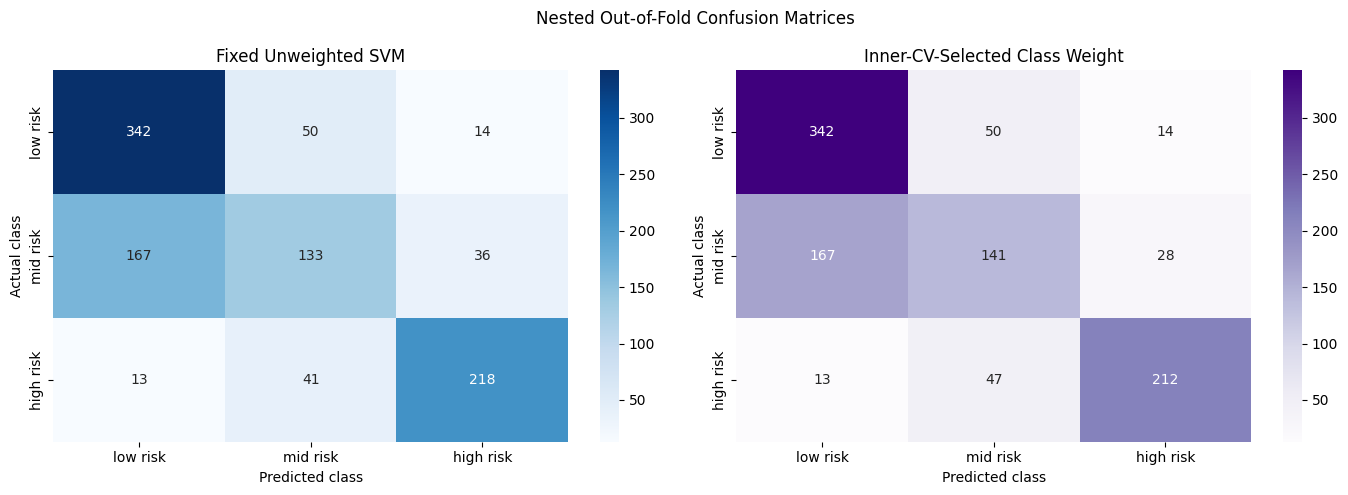


Fixed Unweighted SVM
              precision    recall  f1-score   support

    low risk     0.6552    0.8424    0.7371       406
    mid risk     0.5938    0.3958    0.4750       336
   high risk     0.8134    0.8015    0.8074       272

    accuracy                         0.6834      1014
   macro avg     0.6875    0.6799    0.6732      1014
weighted avg     0.6773    0.6834    0.6691      1014


Inner-CV-Selected Class Weight
              precision    recall  f1-score   support

    low risk     0.6552    0.8424    0.7371       406
    mid risk     0.5924    0.4196    0.4913       336
   high risk     0.8346    0.7794    0.8061       272

    accuracy                         0.6854      1014
   macro avg     0.6941    0.6805    0.6781      1014
weighted avg     0.6825    0.6854    0.6741      1014


KEY CLASSIFICATION ERRORS


,Strategy,Mid risk predicted as low,Mid risk predicted as high,High risk predicted as low,High risk predicted as mid,Correct mid-risk predictions,Correct high-risk predictions
0,Fixed Unweighted SVM,167,36,13,41,133,218
1,Inner-CV-Selected Class Weight,167,28,13,47,141,212


Saved:
- maternalrisk_svm_error_analysis.svg
- maternalrisk_svm_error_summary.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# CELL 22: ERROR ANALYSIS
# Compare baseline and class-weight-selected SVM
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report
from google.colab import files

required = [
    "y",
    "outer_predictions_baseline",
    "outer_predictions_tuned"
]

missing = [name for name in required if name not in globals()]
if missing:
    raise NameError(
        f"Missing variables: {missing}. "
        "The out-of-fold predictions are no longer in memory. "
        "Do not substitute the previously reported summary scores."
    )

actual = np.asarray(y, dtype=str)
baseline_pred = np.asarray(outer_predictions_baseline, dtype=str)
tuned_pred = np.asarray(outer_predictions_tuned, dtype=str)

class_order = ["low risk", "mid risk", "high risk"]

# ------------------------------------------------------------
# 1. Confusion matrices
# ------------------------------------------------------------

cm_baseline = confusion_matrix(
    actual, baseline_pred, labels=class_order
)

cm_tuned = confusion_matrix(
    actual, tuned_pred, labels=class_order
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    cm_baseline,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_order,
    yticklabels=class_order,
    ax=axes[0]
)
axes[0].set_title("Fixed Unweighted SVM")
axes[0].set_xlabel("Predicted class")
axes[0].set_ylabel("Actual class")

sns.heatmap(
    cm_tuned,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=class_order,
    yticklabels=class_order,
    ax=axes[1]
)
axes[1].set_title("Inner-CV-Selected Class Weight")
axes[1].set_xlabel("Predicted class")
axes[1].set_ylabel("Actual class")

plt.suptitle("Nested Out-of-Fold Confusion Matrices")
plt.tight_layout()

plt.savefig(
    "maternalrisk_svm_error_analysis.svg",
    format="svg",
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 2. Classification reports
# ------------------------------------------------------------

for name, predictions in [
    ("Fixed Unweighted SVM", baseline_pred),
    ("Inner-CV-Selected Class Weight", tuned_pred)
]:
    print(f"\n{name}")
    print(
        classification_report(
            actual,
            predictions,
            labels=class_order,
            target_names=class_order,
            digits=4,
            zero_division=0
        )
    )

# ------------------------------------------------------------
# 3. Count the most important class confusions
# ------------------------------------------------------------

error_summary = []

for name, cm in [
    ("Fixed Unweighted SVM", cm_baseline),
    ("Inner-CV-Selected Class Weight", cm_tuned)
]:
    error_summary.append({
        "Strategy": name,
        "Mid risk predicted as low": int(cm[1, 0]),
        "Mid risk predicted as high": int(cm[1, 2]),
        "High risk predicted as low": int(cm[2, 0]),
        "High risk predicted as mid": int(cm[2, 1]),
        "Correct mid-risk predictions": int(cm[1, 1]),
        "Correct high-risk predictions": int(cm[2, 2])
    })

error_df = pd.DataFrame(error_summary)

print("\nKEY CLASSIFICATION ERRORS")
display(error_df)

error_df.to_csv(
    "maternalrisk_svm_error_summary.csv",
    index=False
)

print("Saved:")
print("- maternalrisk_svm_error_analysis.svg")
print("- maternalrisk_svm_error_summary.csv")

files.download("maternalrisk_svm_error_summary.csv")


Baseline held-out macro F1: 0.7148
Permutation importance on outer fold 1:


,Feature,Mean F1 decrease,Importance SD
0,SystolicBP,0.1579,0.0250
1,BodyTemp,0.1251,0.0174
2,DiastolicBP,0.1186,0.0223
3,BS,0.1035,0.0181
4,Age,0.0472,0.0123
5,HeartRate,0.0466,0.0126


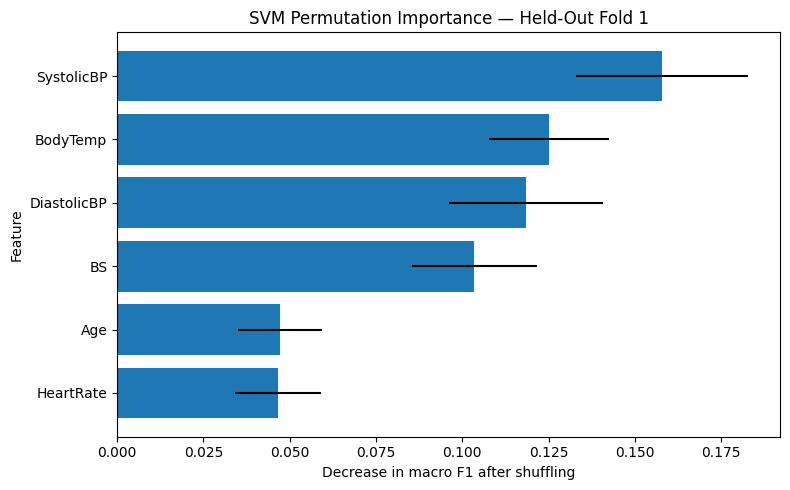

Saved: maternalrisk_svm_permutation_importance.svg


In [ ]:

# ============================================================
# CELL 23: PERMUTATION IMPORTANCE FOR THE SVM
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedGroupKFold

required = ["X", "y", "groups", "folds", "svm_pipeline"]
missing = [name for name in required if name not in globals()]

if missing:
    raise NameError(
        f"Missing variables: {missing}. Run the recovery cells first."
    )

# Use one held-out grouped fold for a demonstration of importance.
# This is exploratory, not a final independent importance estimate.
train_idx, test_idx = folds[0]

X_train = X.iloc[train_idx]
y_train = y.iloc[train_idx]
X_test = X.iloc[test_idx]
y_test = y.iloc[test_idx]

svm_model = clone(svm_pipeline)
svm_model.set_params(
    classifier__C=10,
    classifier__gamma=0.01,
    classifier__class_weight=None
)

svm_model.fit(X_train, y_train)

baseline_score = f1_score(
    y_test,
    svm_model.predict(X_test),
    average="macro",
    zero_division=0
)

importance = permutation_importance(
    svm_model,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=20,
    random_state=42,
    n_jobs=1
)

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Mean F1 decrease": importance.importances_mean,
    "Importance SD": importance.importances_std
}).sort_values(
    "Mean F1 decrease",
    ascending=False
).reset_index(drop=True)

print(f"Baseline held-out macro F1: {baseline_score:.4f}")
print("Permutation importance on outer fold 1:")
display(importance_df.round(4))

# Plot
plot_df = importance_df.sort_values("Mean F1 decrease")

plt.figure(figsize=(8, 5))
plt.barh(
    plot_df["Feature"],
    plot_df["Mean F1 decrease"],
    xerr=plot_df["Importance SD"]
)
plt.axvline(0, linestyle="--")
plt.xlabel("Decrease in macro F1 after shuffling")
plt.ylabel("Feature")
plt.title("SVM Permutation Importance — Held-Out Fold 1")
plt.tight_layout()

plt.savefig(
    "maternalrisk_svm_permutation_importance.svg",
    format="svg",
    bbox_inches="tight"
)
plt.show()

print("Saved: maternalrisk_svm_permutation_importance.svg")


Fold 1/5 complete | held-out macro F1: 0.7148
Fold 2/5 complete | held-out macro F1: 0.6739
Fold 3/5 complete | held-out macro F1: 0.6728
Fold 4/5 complete | held-out macro F1: 0.6118
Fold 5/5 complete | held-out macro F1: 0.6720

HELD-OUT PERFORMANCE BY FOLD


,Fold,Held-out macro F1,Held-out records
0,1,0.7148,170
1,2,0.6739,261
2,3,0.6728,191
3,4,0.6118,203
4,5,0.6720,189



FEATURE IMPORTANCE ACROSS ALL GROUPED FOLDS


,Feature,Mean F1 decrease,Across-fold SD,Mean within-fold permutation SD
0,BS,0.1399,0.0308,0.0219
1,SystolicBP,0.1216,0.0398,0.0218
2,DiastolicBP,0.0822,0.0413,0.0230
3,BodyTemp,0.0703,0.0445,0.0205
4,HeartRate,0.0259,0.0462,0.0133
5,Age,0.0210,0.0333,0.0079


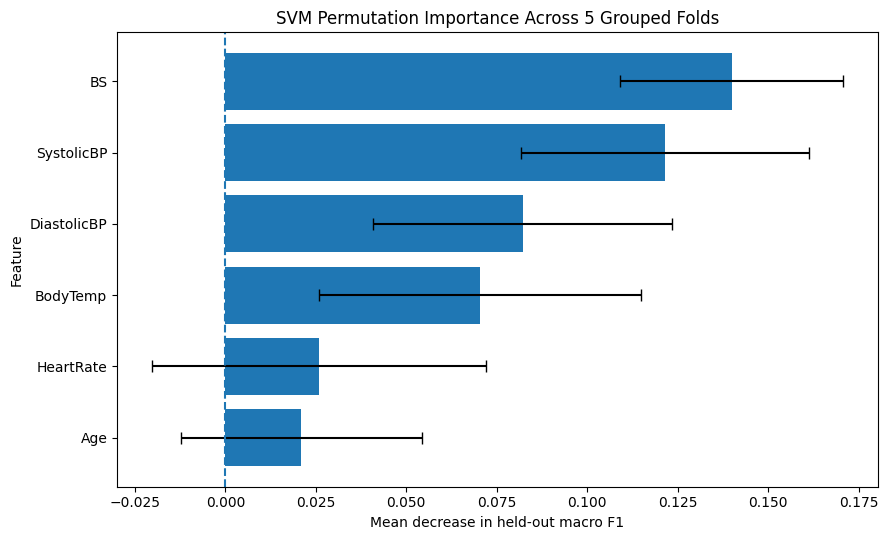


Files created:
maternalrisk_svm_permutation_importance_5fold.svg
maternalrisk_svm_permutation_importance_5fold.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# CELL 24: CROSS-FOLD PERMUTATION IMPORTANCE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score
from google.colab import files

required = ["X", "y", "folds", "svm_pipeline"]
missing = [name for name in required if name not in globals()]

if missing:
    raise NameError(
        f"Missing variables: {missing}. Run the data preparation "
        "and grouped-CV setup cells first."
    )

fold_importance_rows = []
fold_baseline_rows = []

for fold_number, (train_idx, test_idx) in enumerate(folds, start=1):

    X_train = X.iloc[train_idx]
    y_train = y.iloc[train_idx]
    X_test = X.iloc[test_idx]
    y_test = y.iloc[test_idx]

    model = clone(svm_pipeline)
    model.set_params(
        classifier__C=10,
        classifier__gamma=0.01,
        classifier__class_weight=None
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    baseline_f1 = f1_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )

    fold_baseline_rows.append({
        "Fold": fold_number,
        "Held-out macro F1": baseline_f1,
        "Held-out records": len(test_idx)
    })

    perm = permutation_importance(
        model,
        X_test,
        y_test,
        scoring="f1_macro",
        n_repeats=15,
        random_state=42 + fold_number,
        n_jobs=1
    )

    for feature_index, feature_name in enumerate(X.columns):
        fold_importance_rows.append({
            "Fold": fold_number,
            "Feature": feature_name,
            "Mean F1 decrease": perm.importances_mean[feature_index],
            "Permutation SD": perm.importances_std[feature_index]
        })

    print(
        f"Fold {fold_number}/{len(folds)} complete | "
        f"held-out macro F1: {baseline_f1:.4f}"
    )

# Store fold-level results
fold_importance_df = pd.DataFrame(fold_importance_rows)
fold_baselines_df = pd.DataFrame(fold_baseline_rows)

# Aggregate feature importance across the five held-out folds
summary_df = (
    fold_importance_df
    .groupby("Feature")
    .agg(
        Mean_F1_decrease=("Mean F1 decrease", "mean"),
        Across_fold_SD=("Mean F1 decrease", "std"),
        Mean_permutation_SD=("Permutation SD", "mean")
    )
    .reset_index()
    .sort_values("Mean_F1_decrease", ascending=False)
    .reset_index(drop=True)
)

summary_df = summary_df.rename(columns={
    "Mean_F1_decrease": "Mean F1 decrease",
    "Across_fold_SD": "Across-fold SD",
    "Mean_permutation_SD": "Mean within-fold permutation SD"
})

print("\nHELD-OUT PERFORMANCE BY FOLD")
display(fold_baselines_df.round(4))

print("\nFEATURE IMPORTANCE ACROSS ALL GROUPED FOLDS")
display(summary_df.round(4))

# Plot mean importance and across-fold variability
plot_df = summary_df.sort_values("Mean F1 decrease")

plt.figure(figsize=(9, 5.5))
plt.barh(
    plot_df["Feature"],
    plot_df["Mean F1 decrease"],
    xerr=plot_df["Across-fold SD"],
    capsize=4
)
plt.axvline(0, linestyle="--")
plt.xlabel("Mean decrease in held-out macro F1")
plt.ylabel("Feature")
plt.title("SVM Permutation Importance Across 5 Grouped Folds")
plt.tight_layout()

svg_path = "maternalrisk_svm_permutation_importance_5fold.svg"
csv_path = "maternalrisk_svm_permutation_importance_5fold.csv"

plt.savefig(svg_path, format="svg", bbox_inches="tight")
plt.show()

summary_df.to_csv(csv_path, index=False)

print("\nFiles created:")
print(svg_path)
print(csv_path)

files.download(svg_path)
files.download(csv_path)


In [ ]:

# ============================================================
# CELL 25: CONSOLIDATE RESULTS FOR THE RESEARCH REPORT
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    classification_report
)

from google.colab import files

required = [
    "y",
    "outer_predictions_baseline",
    "outer_predictions_tuned",
    "fold_baselines_df",
    "summary_df"
]

missing = [name for name in required if name not in globals()]
if missing:
    raise NameError(
        f"Missing variables: {missing}. "
        "Run the relevant previous cells first."
    )

actual = np.asarray(y, dtype=str)

predictions_by_strategy = {
    "Fixed unweighted SVM": np.asarray(
        outer_predictions_baseline, dtype=str
    ),
    "Inner-CV-selected class weight": np.asarray(
        outer_predictions_tuned, dtype=str
    )
}

class_order = ["low risk", "mid risk", "high risk"]

# 1. Overall metrics
overall_rows = []

for strategy, predictions in predictions_by_strategy.items():
    overall_rows.append({
        "Strategy": strategy,
        "Accuracy": accuracy_score(actual, predictions),
        "Macro precision": precision_score(
            actual, predictions,
            labels=class_order,
            average="macro",
            zero_division=0
        ),
        "Macro recall / balanced accuracy": balanced_accuracy_score(
            actual, predictions
        ),
        "Macro F1": f1_score(
            actual, predictions,
            labels=class_order,
            average="macro",
            zero_division=0
        )
    })

overall_results = pd.DataFrame(overall_rows)

print("OVERALL OUT-OF-FOLD RESULTS")
display(overall_results.round(4))

# 2. Per-class performance
class_rows = []

for strategy, predictions in predictions_by_strategy.items():
    report = classification_report(
        actual,
        predictions,
        labels=class_order,
        output_dict=True,
        zero_division=0
    )

    for risk_class in class_order:
        class_rows.append({
            "Strategy": strategy,
            "Risk class": risk_class,
            "Precision": report[risk_class]["precision"],
            "Recall": report[risk_class]["recall"],
            "F1 score": report[risk_class]["f1-score"],
            "Support": report[risk_class]["support"]
        })

class_results = pd.DataFrame(class_rows)

print("\nPER-CLASS PERFORMANCE")
display(class_results.round(4))

# 3. Fold-level performance
print("\nHELD-OUT FOLD PERFORMANCE")
display(fold_baselines_df.round(4))

# 4. Export result tables
overall_results.to_csv(
    "maternalrisk_overall_results.csv", index=False
)
class_results.to_csv(
    "maternalrisk_classwise_results.csv", index=False
)
fold_baselines_df.to_csv(
    "maternalrisk_fold_performance.csv", index=False
)
summary_df.to_csv(
    "maternalrisk_feature_importance_summary.csv", index=False
)

# 5. Save a concise research notes file
research_notes = """
MaternalRisk AI — Research Notes
================================

Objective
---------
Compare machine-learning classifiers for three-class maternal
health risk classification on the UCI Maternal Health Risk dataset.

Dataset
-------
1014 observations; 6 input features; target: RiskLevel.
Classes: low risk, mid risk, high risk.

Validation
----------
Grouped cross-validation was used to keep identical observed
feature profiles in the same fold. Hyperparameter selection and
exploratory class-weight experiments were also performed.

Interpretation
--------------
SVM was the leading baseline in the experiments conducted.
Mid-risk recall remained a key limitation. Increasing the
mid-risk class weight improved its recall but reduced recall
for other classes in the tested comparison.

Feature importance
------------------
Permutation importance was calculated across five held-out
grouped folds. Blood sugar and systolic blood pressure had the
largest mean F1 decreases when shuffled in this experiment.
Importance is predictive, not causal or clinical evidence.

Limitations
-----------
- The dataset is small and contains repeated feature profiles.
- Identical observed profiles sometimes have conflicting labels.
- Results are cross-validation estimates, not external validation.
- Selecting configurations after inspecting CV results can
  introduce selection optimism.
- The model is a research prototype, not a clinical decision tool.
- Generalization to other populations, including India, is unknown.
"""

Path("maternalrisk_research_notes.txt").write_text(
    research_notes.strip() + "\n",
    encoding="utf-8"
)

print("\nExported results:")
for filename in [
    "maternalrisk_overall_results.csv",
    "maternalrisk_classwise_results.csv",
    "maternalrisk_fold_performance.csv",
    "maternalrisk_feature_importance_summary.csv",
    "maternalrisk_research_notes.txt"
]:
    print("-", filename)

files.download("maternalrisk_overall_results.csv")
files.download("maternalrisk_classwise_results.csv")
files.download("maternalrisk_fold_performance.csv")
files.download("maternalrisk_feature_importance_summary.csv")
files.download("maternalrisk_research_notes.txt")


OVERALL OUT-OF-FOLD RESULTS


,Strategy,Accuracy,Macro precision,Macro recall / balanced accuracy,Macro F1
0,Fixed unweighted SVM,0.6834,0.6875,0.6799,0.6732
1,Inner-CV-selected class weight,0.6854,0.6941,0.6805,0.6781



PER-CLASS PERFORMANCE


,Strategy,Risk class,Precision,Recall,F1 score,Support
0,Fixed unweighted SVM,low risk,0.6552,0.8424,0.7371,406.0
1,Fixed unweighted SVM,mid risk,0.5938,0.3958,0.4750,336.0
2,Fixed unweighted SVM,high risk,0.8134,0.8015,0.8074,272.0
3,Inner-CV-selected class weight,low risk,0.6552,0.8424,0.7371,406.0
4,Inner-CV-selected class weight,mid risk,0.5924,0.4196,0.4913,336.0
5,Inner-CV-selected class weight,high risk,0.8346,0.7794,0.8061,272.0



HELD-OUT FOLD PERFORMANCE


,Fold,Held-out macro F1,Held-out records
0,1,0.7148,170
1,2,0.6739,261
2,3,0.6728,191
3,4,0.6118,203
4,5,0.6720,189


... (7 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>